# Proyecto Segundo Corte: Predicción del PIB con un perceptrón simple

**Fundamentos de Inteligencia Artificial (IAIA) — 2026-2**

**Integrantes:** Santiago Córdoba, César Morales

**Dataset:** *Global Economy Indicators* (Kaggle) <cite data-cite="globaleconomy"></cite>

**Tipo de problema:** regresión (predicción numérica)

**Herramientas:** `pandas`, `numpy`, `matplotlib`, `seaborn` y `keras`

## Contenido

1. Diseño del problema y del modelo
2. Carga de datos
3. Exploración inicial
4. Limpieza
5. Análisis exploratorio (EDA)
6. Selección de características, matrices $X$ e $y$ y división train/test
7. Escalamiento
8. Perceptrón implementado a mano con NumPy (como en el Lab 04)
9. Perceptrón con Keras
10. Entrenamiento y actualización de los pesos
11. Curva de pérdida
12. Evaluación en el conjunto de prueba
13. ¿Qué aprendió el perceptrón?
14. Limitaciones y conclusiones
15. Referencias

## 1. Diseño del problema y del modelo

### El problema

El Producto Interno Bruto (PIB o GDP) es el valor de todos los bienes y servicios finales que produce un país en un año. Queremos **predecir el PIB de un país en un año dado** a partir de otros indicadores de sus cuentas nacionales.

Como el PIB es un valor numérico continuo (en dólares), el problema es de **regresión**, no de clasificación.

### Entradas (X) y salida (y)

- **Variable objetivo $y$:** `Gross Domestic Product (GDP)`, en USD.
- **Características $X$ (8 variables):**
  - $C$: consumo de los hogares (`Household consumption expenditure ...`)
  - $G$: consumo del gobierno (`General government final consumption expenditure`)
  - $I$: inversión (`Gross capital formation`)
  - $X$: exportaciones (`Exports of goods and services`)
  - $M$: importaciones (`Imports of goods and services`)
  - Valor agregado de la agricultura (`Agriculture, hunting, forestry, fishing (ISIC A-B)`)
  - Valor agregado de la manufactura (`Manufacturing (ISIC D)`)
  - Población (`Population`)

### Por qué escogimos estas variables

En macroeconomía, el PIB calculado por el método del gasto cumple la identidad:

$$PIB = C + G + I + X - M$$

Esto quiere decir que la relación entre las primeras cinco variables y el PIB debería ser **lineal**. Por eso un perceptrón simple, que es un modelo lineal, tiene sentido para este problema. También nos da una forma de **comprobar** el modelo: si el perceptrón aprende bien, sus pesos (pasados a dólares) deberían quedar cerca de $+1$ para $C$, $G$, $I$, $X$ y cerca de $-1$ para $M$. Agricultura, manufactura y población las dejamos para ver si el modelo descubre por sí solo que casi no aportan una vez tiene los componentes del gasto.

Sabemos que con esto el problema es "fácil" para el modelo, y lo discutimos en la sección 4 cuando hablamos de *data leakage*. Lo interesante no es sacar un $R^2$ alto sino ver si el descenso de gradiente llega a la relación que ya conocemos de la teoría.

### Configuración del perceptrón

| Elemento | Elección | Justificación |
|---|---|---|
| Arquitectura | `Dense(1)`: 8 entradas → 1 neurona | Es un perceptrón simple, sin capas ocultas |
| Activación de salida | Lineal (identidad), $g(z) = z$ | El PIB puede tomar cualquier valor real; una sigmoide lo encerraría entre 0 y 1 |
| Función de pérdida | Error cuadrático medio (MSE) | Es la pérdida estándar para regresión (Lab 04) |
| Optimizador | SGD con momentum | Es descenso de gradiente; el momentum ayuda porque las variables están muy correlacionadas |
| Métrica extra | MAE | Más fácil de interpretar que el MSE |

La neurona calcula:

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_8 x_8 + b$$

y la pérdida que se minimiza es:

$$MSE = \frac{1}{m}\sum_{i=1}^{m}(y_i - \hat{y}_i)^2$$

## 2. Carga de datos

Importamos las librerías. Fijamos una semilla para que los resultados salgan iguales cada vez que se ejecute el notebook.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
sns.set_style("whitegrid")

print("pandas:", pd.__version__)
print("numpy :", np.__version__)
print("keras :", keras.__version__)

ImportError: DLL load failed while importing missing: Una directiva de Control de aplicaciones bloqueó este archivo.

In [ ]:
# el csv esta en la carpeta archive/ del proyecto
ruta_csv = os.path.join("archive", "Global Economy Indicators.csv")
#Para funcionamiento local
if not os.path.exists(ruta_csv):
    ruta_csv = r"C:\Users\cordo\OneDrive\Documents\IAIA\Proyecto_SegundoCorte\archive\Global Economy Indicators.csv"

df_raw = pd.read_csv(ruta_csv)
print("Filas y columnas:", df_raw.shape)
df_raw.head()

Filas y columnas: (10512, 26)


,CountryID,Country,Year,AMA exchange rate,IMF based exchange rate,Population,Currency,Per capita GNI,"Agriculture, hunting, forestry, fishing (ISIC A-B)",Changes in inventories,...,Household consumption expenditure (including Non-profit institutions serving households),Imports of goods and services,Manufacturing (ISIC D),"Mining, Manufacturing, Utilities (ISIC C-E)",Other Activities (ISIC J-P),Total Value Added,"Transport, storage and communication (ISIC I)","Wholesale, retail trade, restaurants and hotels (ISIC G-H)",Gross National Income(GNI) in USD,Gross Domestic Product (GDP)
0,4,Afghanistan,1970,0.044998,0.044998,10752971,Afghani,164,8.699174e+08,NaN,...,1.551094e+09,195277226.0,370146827.0,376690811.0,127747843.0,1.731454e+09,83917200.0,226387091.0,1.766528e+09,1.731436e+09
1,4,Afghanistan,1971,0.044998,0.044998,11015857,Afghani,168,9.108281e+08,NaN,...,1.675426e+09,276296480.0,387549502.0,394401164.0,133754097.0,1.812857e+09,87860382.0,237019196.0,1.850122e+09,1.812838e+09
2,4,Afghanistan,1972,0.044998,0.044998,11286753,Afghani,149,8.279453e+08,NaN,...,1.498812e+09,290370350.0,352284669.0,358512865.0,121582672.0,1.647918e+09,79864525.0,215477287.0,1.683948e+09,1.647900e+09
3,4,Afghanistan,1973,0.044998,0.044998,11575305,Afghani,150,8.554869e+08,NaN,...,1.508024e+09,262962880.0,364010279.0,370445793.0,125630236.0,1.702735e+09,82528885.0,222624293.0,1.739998e+09,1.702716e+09
4,4,Afghanistan,1974,0.044998,0.044998,11869879,Afghani,177,1.035913e+09,NaN,...,1.778819e+09,305679151.0,440760406.0,448552790.0,152119162.0,2.061752e+09,99918604.0,269525910.0,2.106420e+09,2.061729e+09


## 3. Exploración inicial

Antes de tocar los datos revisamos qué tenemos: tipos de dato, nulos, estadísticas básicas y valores únicos (como en el Paso 1 del Lab 03).

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10512 entries, 0 to 10511
Data columns (total 26 columns):
 #   Column                                                                                      Non-Null Count  Dtype  
---  ------                                                                                      --------------  -----  
 0    CountryID                                                                                  10512 non-null  int64  
 1    Country                                                                                    10512 non-null  str    
 2    Year                                                                                       10512 non-null  int64  
 3    AMA exchange rate                                                                          10512 non-null  float64
 4    IMF based exchange rate                                                                    10512 non-null  float64
 5    Population                                       

In [4]:
# los nombres de las columnas vienen con espacios al inicio y al final
print(df_raw.columns[:5].tolist())
print(repr(df_raw.iloc[0, 1]))

[' CountryID ', ' Country ', ' Year ', ' AMA exchange rate ', ' IMF based exchange rate ']
' Afghanistan '


Encontramos un problema de formato: tanto los nombres de las columnas como los textos (por ejemplo `' Afghanistan '`) tienen espacios al inicio y al final. Si no se corrige, un filtro como `df["Country"] == "Colombia"` no encuentra nada. Lo arreglamos en la limpieza.

In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
CountryID,10512.0,4.311166e+02,2.511691e+02,4.000000e+00,2.120000e+02,4.300000e+02,6.430000e+02,8.940000e+02
Year,10512.0,1.996263e+03,1.490036e+01,1.970000e+03,1.984000e+03,1.997000e+03,2.009000e+03,2.021000e+03
AMA exchange rate,10512.0,3.573959e+02,2.291128e+03,4.300000e-14,1.000000e+00,2.812895e+00,5.134316e+01,1.116366e+05
IMF based exchange rate,10512.0,3.419846e+02,1.941857e+03,4.300000e-14,1.000000e+00,2.761315e+00,4.806684e+01,4.200000e+04
Population,10512.0,2.851523e+07,1.141296e+08,4.359000e+03,6.330615e+05,5.051556e+06,1.678862e+07,1.425893e+09
Per capita GNI,10512.0,8.965565e+03,1.707021e+04,3.400000e+01,7.300000e+02,2.316500e+03,8.965750e+03,2.343170e+05
"Agriculture, hunting, forestry, fishing (ISIC A-B)",10391.0,7.793212e+09,4.034349e+10,2.813900e+04,1.304522e+08,9.313674e+08,4.023326e+09,1.350000e+12
Changes in inventories,8671.0,1.626543e+09,8.932353e+09,-1.510000e+11,4.673545e+05,6.829635e+07,6.910750e+08,2.110000e+11
Construction (ISIC F),10512.0,1.002199e+10,4.985596e+10,1.577280e+05,6.815523e+07,3.717701e+08,2.815730e+09,1.240000e+12
Exports of goods and services,10491.0,4.671176e+10,1.748857e+11,-1.669759e+09,4.026725e+08,2.407906e+09,1.542492e+10,3.530000e+12


## 4. Limpieza

### 4.1 Espacios en nombres y textos

In [6]:
df = df_raw.copy()
df.columns = df.columns.str.strip()

columnas_texto = ["Country", "Currency"]
for col in columnas_texto:
    df[col] = df[col].str.strip()

print(repr(df["Country"].iloc[0]))
print("Paises distintos:", df["Country"].nunique())
print("Monedas distintas:", df["Currency"].nunique())
print("Años:", df["Year"].min(), "a", df["Year"].max())

'Afghanistan'
Paises distintos: 220
Monedas distintas: 153
Años: 1970 a 2021


### 4.2 Duplicados y cantidad de países por año

Filas duplicadas: 0
Filas repetidas pais-año: 0


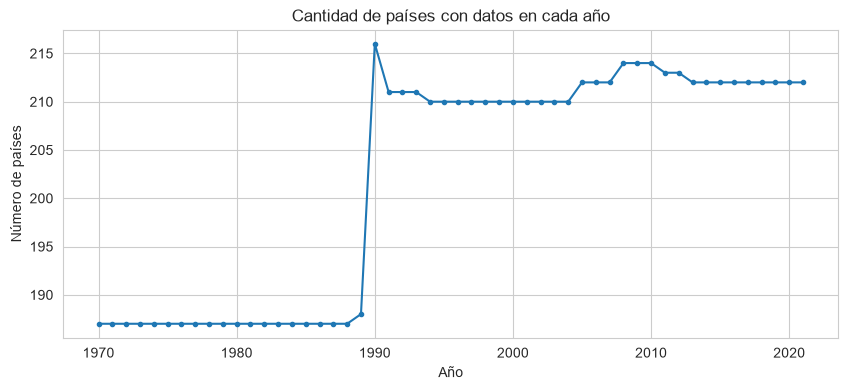

In [7]:
print("Filas duplicadas:", df.duplicated().sum())
print("Filas repetidas pais-año:", df.duplicated(subset=["Country", "Year"]).sum())

paises_por_anio = df.groupby("Year")["Country"].nunique()

plt.figure(figsize=(10, 4))
plt.plot(paises_por_anio.index, paises_por_anio.values, marker="o", markersize=3)
plt.title("Cantidad de países con datos en cada año")
plt.xlabel("Año")
plt.ylabel("Número de países")
plt.show()

No hay filas duplicadas ni países repetidos en un mismo año. El número de países cambia con el tiempo: entre 1970 y 1989 hay 187 y después sube a más de 210. Esto tiene sentido históricamente, porque al disolverse la URSS, Yugoslavia y Checoslovaquia aparecen países nuevos. No es un error de los datos, pero significa que el panel no está balanceado.

### 4.3 Valores faltantes

In [ ]:
nulos = df.isnull().sum()
tabla_nulos = pd.DataFrame({
    "nulos": nulos,
    "porcentaje": (nulos / len(df) * 100).round(2)
})
tabla_nulos[tabla_nulos["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,porcentaje
Changes in inventories,1841,17.51
"Agriculture, hunting, forestry, fishing (ISIC A-B)",121,1.15
General government final consumption expenditure,52,0.49
Gross fixed capital formation (including Acquisitions less disposals of valuables),52,0.49
Gross capital formation,52,0.49
Household consumption expenditure (including Non-profit institutions serving households),52,0.49
"Wholesale, retail trade, restaurants and hotels (ISIC G-H)",49,0.47
"Transport, storage and communication (ISIC I)",49,0.47
Manufacturing (ISIC D),43,0.41
Imports of goods and services,42,0.40


La única columna con muchos faltantes es `Changes in inventories` (17.5 %). Las demás tienen menos del 1.2 %. Como no vamos a usar `Changes in inventories` (ya está incluida dentro de `Gross capital formation`), no hace falta rellenarla. Para las variables que sí usamos, eliminamos las filas incompletas con `dropna()`, igual que en el Lab 04. Rellenar con la media no tendría sentido aquí, porque el PIB de Afganistán y el de Estados Unidos no tienen nada que ver.

### 4.4 Columnas que no usamos y data leakage

In [9]:
objetivo = "Gross Domestic Product (GDP)"

corr_gdp = df.select_dtypes(include="number").corr()[objetivo].drop(objetivo)
corr_gdp.sort_values(ascending=False).round(4)

Gross National Income(GNI) in USD                                                           0.9999
Total Value Added                                                                           0.9995
Wholesale, retail trade, restaurants and hotels (ISIC G-H)                                  0.9916
Transport, storage and communication (ISIC I)                                               0.9912
General government final consumption expenditure                                            0.9906
Final consumption expenditure                                                               0.9899
Household consumption expenditure (including Non-profit institutions serving households)    0.9826
Other Activities (ISIC J-P)                                                                 0.9812
Construction (ISIC F)                                                                       0.9639
Gross fixed capital formation (including Acquisitions less disposals of valuables)          0.9487
Gross capi

De aquí sacamos varias decisiones:

- **`CountryID` y `Country`:** son identificadores. `CountryID` es un número, pero el país 840 no "vale más" que el país 4, así que no tiene sentido usarlo como variable numérica. `Country` lo guardamos solo para poder mirar resultados por país.
- **`Currency`:** es un texto con el nombre de la moneda y no aporta a la predicción en dólares.
- **`Gross National Income(GNI) in USD` (correlación 0.9999) y `Total Value Added` (0.9995):** son prácticamente el mismo PIB medido de otra forma (GNI = PIB + ingresos netos del exterior; PIB = valor agregado + impuestos − subsidios). Usarlos sería *data leakage*: el modelo estaría "copiando" la respuesta.
- **`Per capita GNI`:** es el GNI dividido por la población, así que tiene el mismo problema.
- **Tasas de cambio:** no tienen relación lineal con el PIB (correlación cercana a 0).

**¿Y los componentes del gasto?** Hay que ser honestos: $C + G + I + X - M$ también reconstruye el PIB, así que en cierto sentido también hay una fuga de información. La diferencia es que aquí el modelo no recibe la respuesta en una sola columna. Tiene que *descubrir* qué peso dar a cada componente y con qué signo, y eso es justamente lo que queremos ver. En la sección 5 comprobamos qué tan bien se cumple la identidad en los datos.

## 5. Análisis exploratorio (EDA)

Para cada gráfica anotamos qué muestra, qué observamos y qué decisión tomamos a partir de ella.

Para que los nombres de las gráficas sean cortos usamos este diccionario:

In [10]:
nombres_cortos = {
    "Household consumption expenditure (including Non-profit institutions serving households)": "Consumo hogares (C)",
    "General government final consumption expenditure": "Consumo gobierno (G)",
    "Gross capital formation": "Inversión (I)",
    "Exports of goods and services": "Exportaciones (X)",
    "Imports of goods and services": "Importaciones (M)",
    "Agriculture, hunting, forestry, fishing (ISIC A-B)": "Agricultura",
    "Manufacturing (ISIC D)": "Manufactura",
    "Population": "Población",
    "Gross Domestic Product (GDP)": "PIB",
}

### Gráfica 1: distribución del PIB

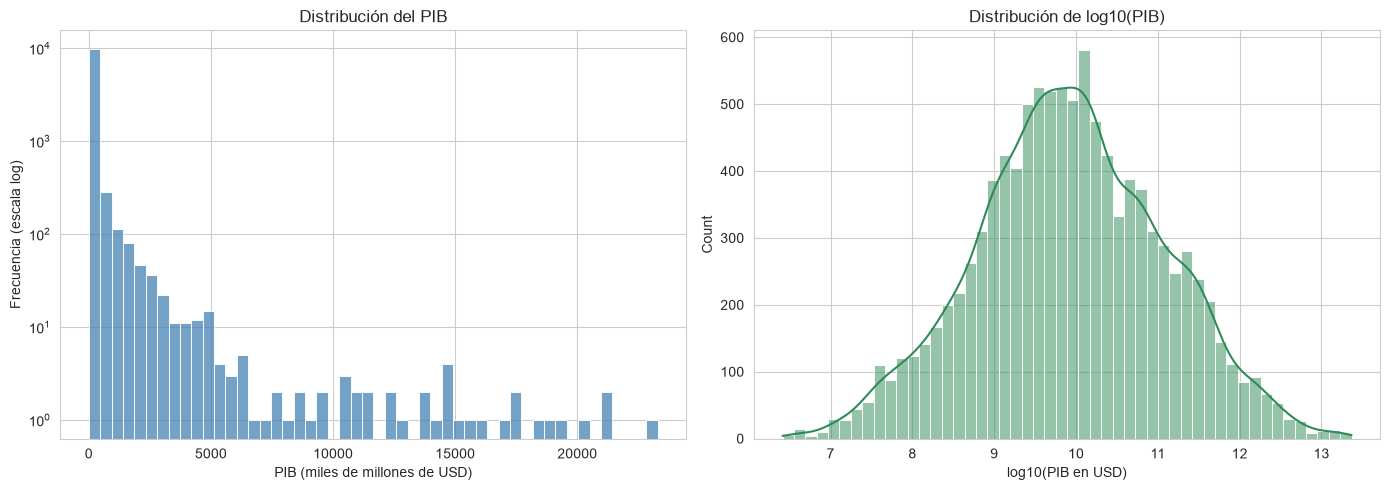

Media:    182.9 miles de millones USD
Mediana:  8.1 miles de millones USD
Asimetría: 13.19


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df[objetivo] / 1e9, bins=50, color="steelblue", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Distribución del PIB")
axes[0].set_xlabel("PIB (miles de millones de USD)")
axes[0].set_ylabel("Frecuencia (escala log)")

sns.histplot(np.log10(df[objetivo]), bins=50, kde=True, color="seagreen", ax=axes[1])
axes[1].set_title("Distribución de log10(PIB)")
axes[1].set_xlabel("log10(PIB en USD)")

plt.tight_layout()
plt.show()

print(f"Media:    {df[objetivo].mean() / 1e9:,.1f} miles de millones USD")
print(f"Mediana:  {df[objetivo].median() / 1e9:,.1f} miles de millones USD")
print(f"Asimetría: {df[objetivo].skew():.2f}")

**Qué muestra:** la distribución del PIB, en escala normal (izquierda) y en logaritmo (derecha).

**Qué observamos:** la distribución es muy asimétrica (asimetría ≈ 13.2). La mediana es de unos 8 mil millones de USD, pero la media es de 183 mil millones, porque unos pocos países (Estados Unidos, China, Japón) tienen valores enormes. En escala logarítmica la forma es mucho más simétrica.

**Decisión:** los valores van desde millones hasta billones de dólares. Si entrenamos el perceptrón con los datos crudos, los errores al cuadrado serían del orden de $10^{24}$ y el descenso de gradiente se desbordaría. **Hay que escalar $X$ y también $y$** (lo comprobamos en la sección 8).

### Gráfica 2: el PIB a través de las décadas

Usamos `pd.cut()` para clasificar las economías por tamaño y vemos cómo cambia la proporción con los años.

In [2]:
df["Decada"] = (df["Year"] // 10 * 10).astype(str) + "s"

df["Tamaño economía"] = pd.cut(
    df[objetivo],
    bins=[0, 10e9, 500e9, np.inf],
    labels=["Pequeña (<10 mil M)", "Mediana (10–500 mil M)", "Grande (>500 mil M)"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df, x="Decada", y=objetivo, hue="Decada", legend=False, palette="Blues", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("PIB por década")
axes[0].set_xlabel("Década")
axes[0].set_ylabel("PIB en USD (escala log)")

sns.countplot(data=df, x="Decada", hue="Tamaño economía", palette="viridis", ax=axes[1])
axes[1].set_title("Tamaño de las economías por década")
axes[1].set_xlabel("Década")
axes[1].set_ylabel("Cantidad de observaciones")

plt.tight_layout()
plt.show()

df.groupby("Decada")[objetivo].median().apply(lambda v: f"{v / 1e9:,.1f} mil M")

NameError: name 'df' is not defined

**Qué muestra:** el PIB de cada década (izquierda) y cuántas observaciones hay de cada tamaño de economía (derecha).

**Qué observamos:** la mediana sube década tras década (de unos 2 mil millones en los 70 a casi 24 mil millones en los 2010). Las economías "grandes" casi no aparecen en los 70 y son cada vez más comunes. Parte de esto es crecimiento real y parte es inflación, porque los valores están en dólares corrientes.

**Decisión:** los datos tienen una tendencia en el tiempo. Si hiciéramos una división aleatoria, el modelo podría entrenar con 2020 y probar con 2015, que es como "ver el futuro". Por eso hacemos una **división temporal**: entrenar con los años viejos y probar con los recientes.

### Gráfica 3: correlaciones

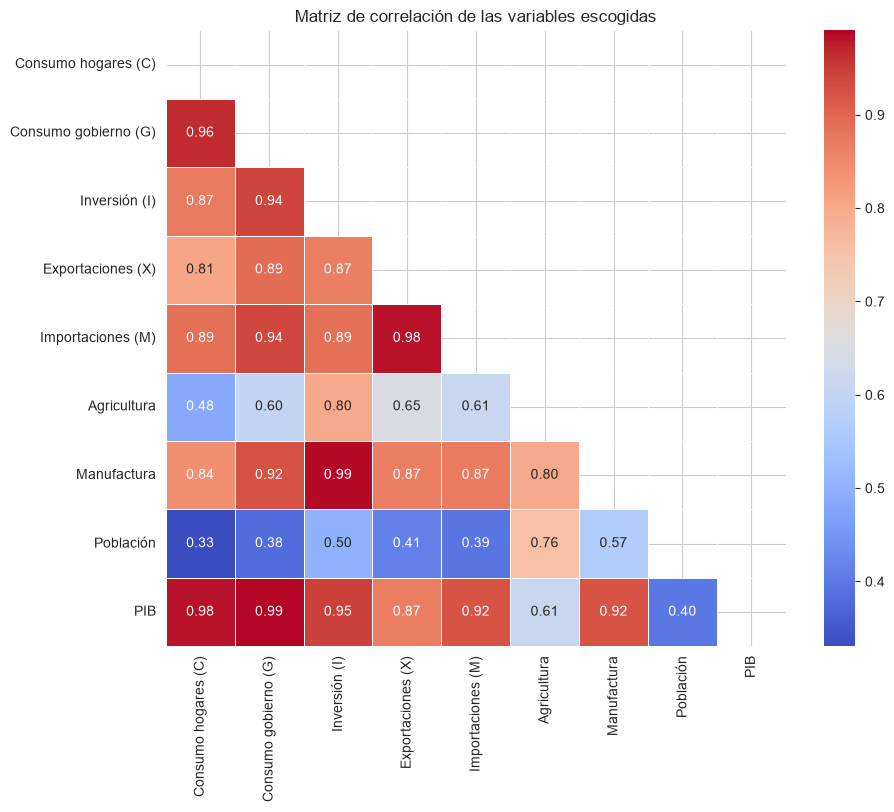

In [13]:
features = [
    "Household consumption expenditure (including Non-profit institutions serving households)",
    "General government final consumption expenditure",
    "Gross capital formation",
    "Exports of goods and services",
    "Imports of goods and services",
    "Agriculture, hunting, forestry, fishing (ISIC A-B)",
    "Manufacturing (ISIC D)",
    "Population",
]

corr = df[features + [objetivo]].corr().rename(index=nombres_cortos, columns=nombres_cortos)

plt.figure(figsize=(10, 8))
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Matriz de correlación de las variables escogidas")
plt.show()

**Qué muestra:** la correlación de Pearson entre las 8 variables de entrada y el PIB.

**Qué observamos:** los componentes del gasto tienen correlaciones muy altas con el PIB (consumo del gobierno 0.99, consumo de hogares 0.98, inversión 0.95, importaciones y manufactura 0.92, exportaciones 0.87). La población (0.40) y la agricultura (0.61) se relacionan menos. También se ve que **las variables de entrada están muy correlacionadas entre sí** (por ejemplo, exportaciones e importaciones 0.98).

**Decisión:** la relación lineal fuerte apoya el uso de un perceptrón lineal. La correlación entre entradas (multicolinealidad) nos avisa que los pesos individuales pueden tardar en estabilizarse durante el entrenamiento, aunque las predicciones sean buenas. Esto lo tenemos en cuenta al escoger el optimizador (SGD con momentum).

### Gráfica 4: relación de cada componente con el PIB

En escala lineal casi todos los puntos quedan apretados en una esquina, así que graficamos en escala log-log.

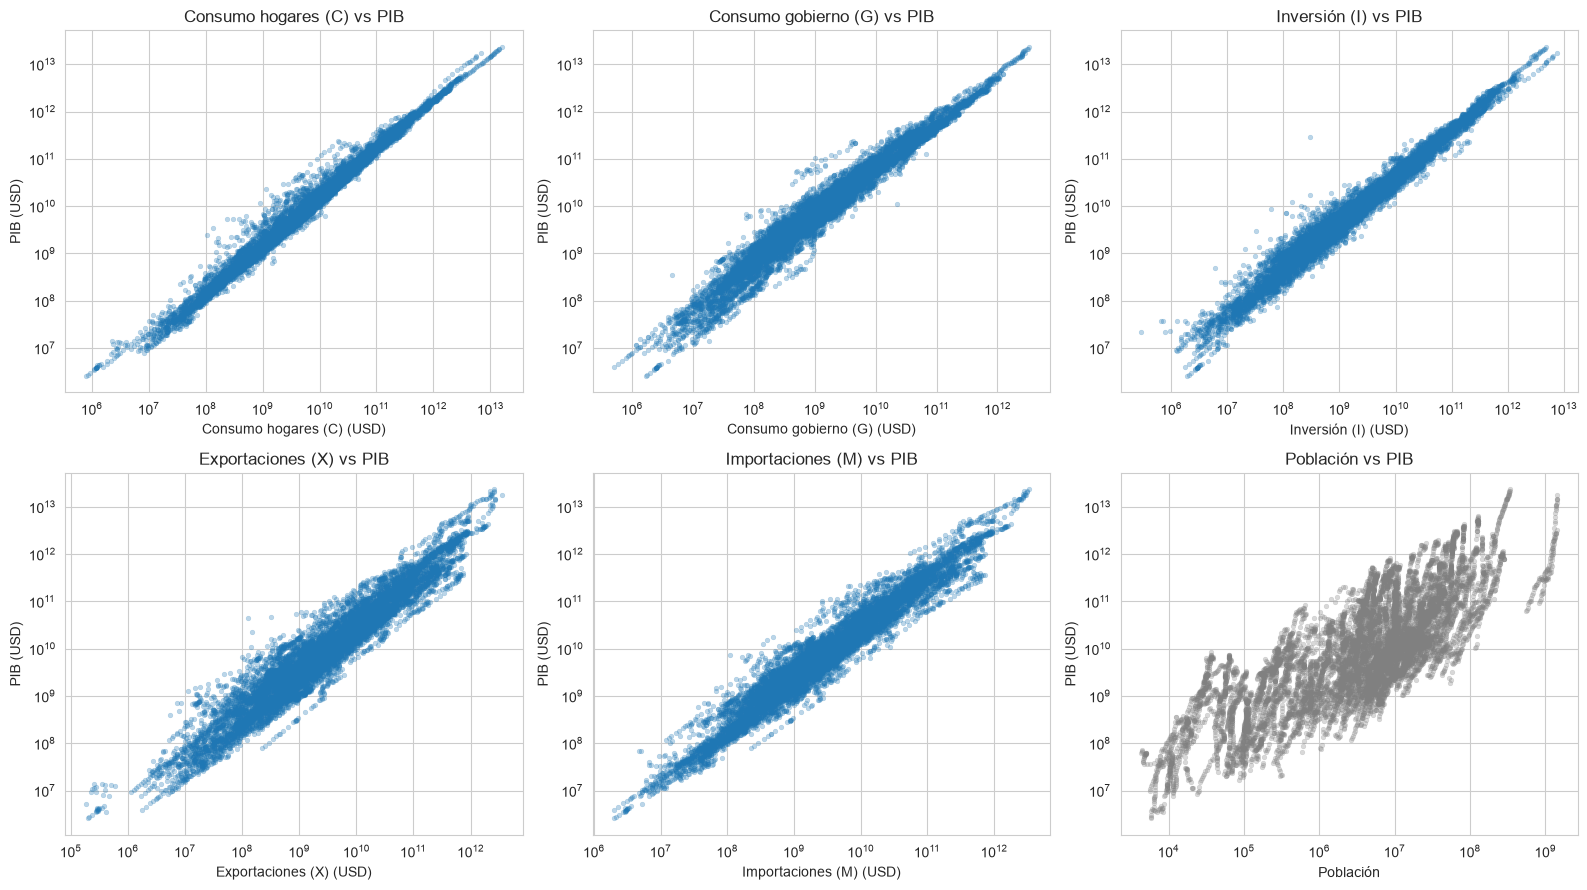

In [14]:
componentes = features[:5]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(componentes):
    sns.scatterplot(x=df[col], y=df[objetivo], alpha=0.3, s=12, edgecolor=None, ax=axes[i])
    axes[i].set_xscale("log")
    axes[i].set_yscale("log")
    axes[i].set_title(f"{nombres_cortos[col]} vs PIB")
    axes[i].set_xlabel(nombres_cortos[col] + " (USD)")
    axes[i].set_ylabel("PIB (USD)")

# ultimo panel: poblacion
sns.scatterplot(x=df["Population"], y=df[objetivo], alpha=0.3, s=12, color="gray", edgecolor=None, ax=axes[5])
axes[5].set_xscale("log")
axes[5].set_yscale("log")
axes[5].set_title("Población vs PIB")
axes[5].set_xlabel("Población")
axes[5].set_ylabel("PIB (USD)")

plt.tight_layout()
plt.show()

**Qué muestra:** cada componente del gasto contra el PIB, y la población contra el PIB.

**Qué observamos:** el consumo de hogares, el consumo del gobierno y la inversión forman nubes muy delgadas y rectas. Exportaciones e importaciones también son lineales pero con más dispersión, porque hay países muy abiertos al comercio (por ejemplo Singapur o Luxemburgo) y otros muy cerrados. La población tiene una nube mucho más ancha: dos países con la misma población pueden tener PIB muy distintos.

**Decisión:** las cinco componentes del gasto son buenos predictores lineales. Esperamos que el modelo le dé poco peso a la población.

### Gráfica 5: ¿se cumple la identidad del PIB en los datos?

Antes de entrenar verificamos si de verdad $PIB \approx C + G + I + X - M$ en este dataset.

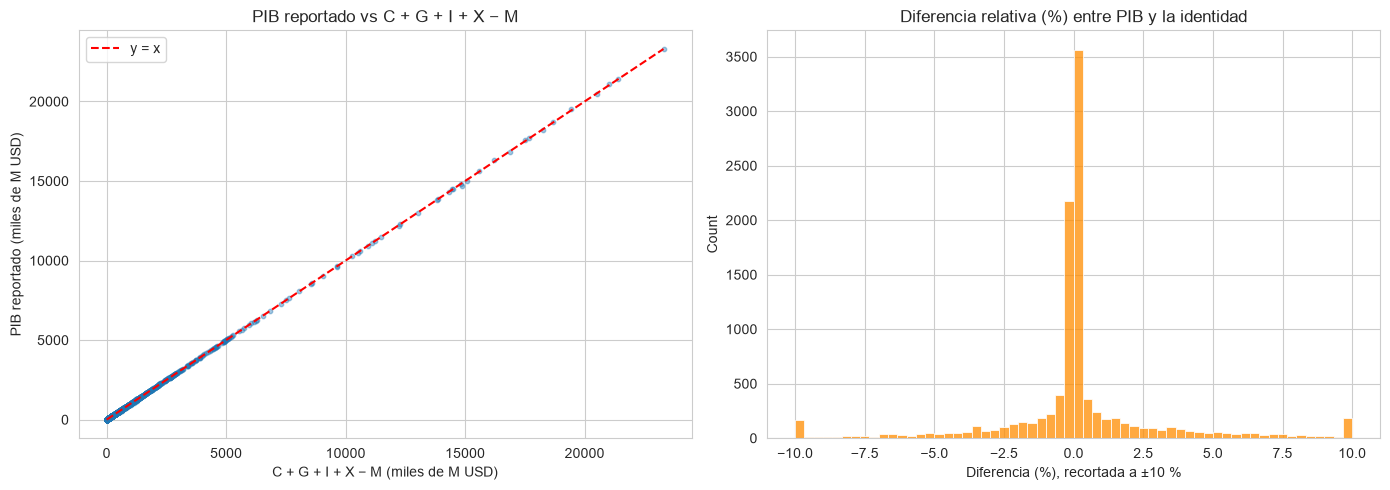

count    10418.000
mean         0.157
std          3.706
min        -40.418
25%         -0.174
50%          0.000
75%          0.262
max         37.995
dtype: float64
Observaciones con diferencia menor al 1 %: 66.3%


In [15]:
c, g, i, x, m = componentes
pib_identidad = df[c] + df[g] + df[i] + df[x] - df[m]
dif_relativa = (df[objetivo] - pib_identidad) / df[objetivo] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(pib_identidad / 1e9, df[objetivo] / 1e9, s=10, alpha=0.4)
lim = df[objetivo].max() / 1e9
axes[0].plot([0, lim], [0, lim], "r--", label="y = x")
axes[0].set_title("PIB reportado vs C + G + I + X − M")
axes[0].set_xlabel("C + G + I + X − M (miles de M USD)")
axes[0].set_ylabel("PIB reportado (miles de M USD)")
axes[0].legend()

sns.histplot(dif_relativa.dropna().clip(-10, 10), bins=60, color="darkorange", ax=axes[1])
axes[1].set_title("Diferencia relativa (%) entre PIB y la identidad")
axes[1].set_xlabel("Diferencia (%), recortada a ±10 %")

plt.tight_layout()
plt.show()

print(dif_relativa.describe().round(3))
print("Observaciones con diferencia menor al 1 %:", f"{(dif_relativa.abs() < 1).mean():.1%}")

**Qué muestra:** el PIB reportado contra el PIB que se obtiene sumando los componentes, y la distribución de la diferencia entre los dos.

**Qué observamos:** los puntos quedan sobre la diagonal y la mediana de la diferencia es exactamente 0 %. La mitad de las observaciones tiene diferencias entre −0.2 % y +0.3 %, y dos de cada tres tienen diferencias menores al 1 %. Las diferencias grandes son pocas y vienen de la "discrepancia estadística" que tienen las cuentas nacionales de algunos países pequeños (en el histograma se acumulan en los extremos porque recortamos a ±10 %).

**Decisión:** la identidad se cumple en los datos, así que ya sabemos qué pesos "ideales" debería encontrar el perceptrón: $+1, +1, +1, +1, -1$ para $C, G, I, X, M$, y cerca de 0 para las demás. Esto nos sirve para evaluar no solo el error del modelo, sino también si aprendió algo con sentido.

### Gráfica 6: evolución del PIB en algunos países

Países graficados: ['United States', 'China', 'Japan', 'Germany', 'India', 'Colombia']


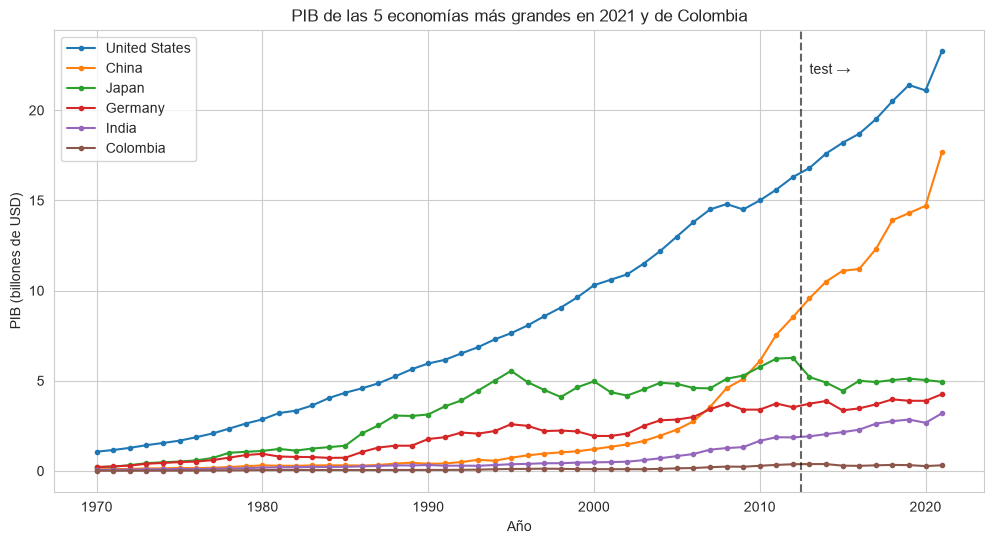

In [16]:
top_2021 = df[df["Year"] == 2021].nlargest(5, objetivo)["Country"].tolist()
paises = top_2021 + ["Colombia"]
print("Países graficados:", paises)

plt.figure(figsize=(12, 6))
for pais in paises:
    datos_pais = df[df["Country"] == pais].sort_values("Year")
    plt.plot(datos_pais["Year"], datos_pais[objetivo] / 1e12, marker="o", markersize=3, label=pais)

plt.axvline(2012.5, color="black", linestyle="--", alpha=0.6)
plt.text(2013, plt.ylim()[1] * 0.9, "test →")
plt.title("PIB de las 5 economías más grandes en 2021 y de Colombia")
plt.xlabel("Año")
plt.ylabel("PIB (billones de USD)")
plt.legend()
plt.show()

**Qué muestra:** la serie del PIB de las cinco economías más grandes de 2021 y de Colombia. La línea punteada marca dónde empieza el conjunto de prueba.

**Qué observamos:** Estados Unidos crece casi todo el tiempo. China despega después del 2000 y en la última década queda en segundo lugar. Japón tiene un pico a mediados de los 90 y en 2012 y luego baja (en dólares). En 2009 y 2020 se ven caídas por la crisis financiera y la pandemia. Colombia, en comparación, aparece casi plana en esta escala.

**Decisión:** en el período de prueba (2013–2021) China alcanza valores que nunca vio el modelo en entrenamiento. Esto pone a prueba la capacidad del perceptrón de **extrapolar**. Un modelo lineal puede extrapolar bien si la relación sigue siendo la misma (en este caso la identidad del PIB no cambia con los años).

### Gráfica 7: pairplot de las variables (en log10)

Tomamos una muestra para que la gráfica no quede saturada.

c:\Users\cordo\OneDrive\Documents\IAIA\Proyecto_SegundoCorte\.venv\Lib\site-packages\pandas\core\internals\blocks.py:347: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)


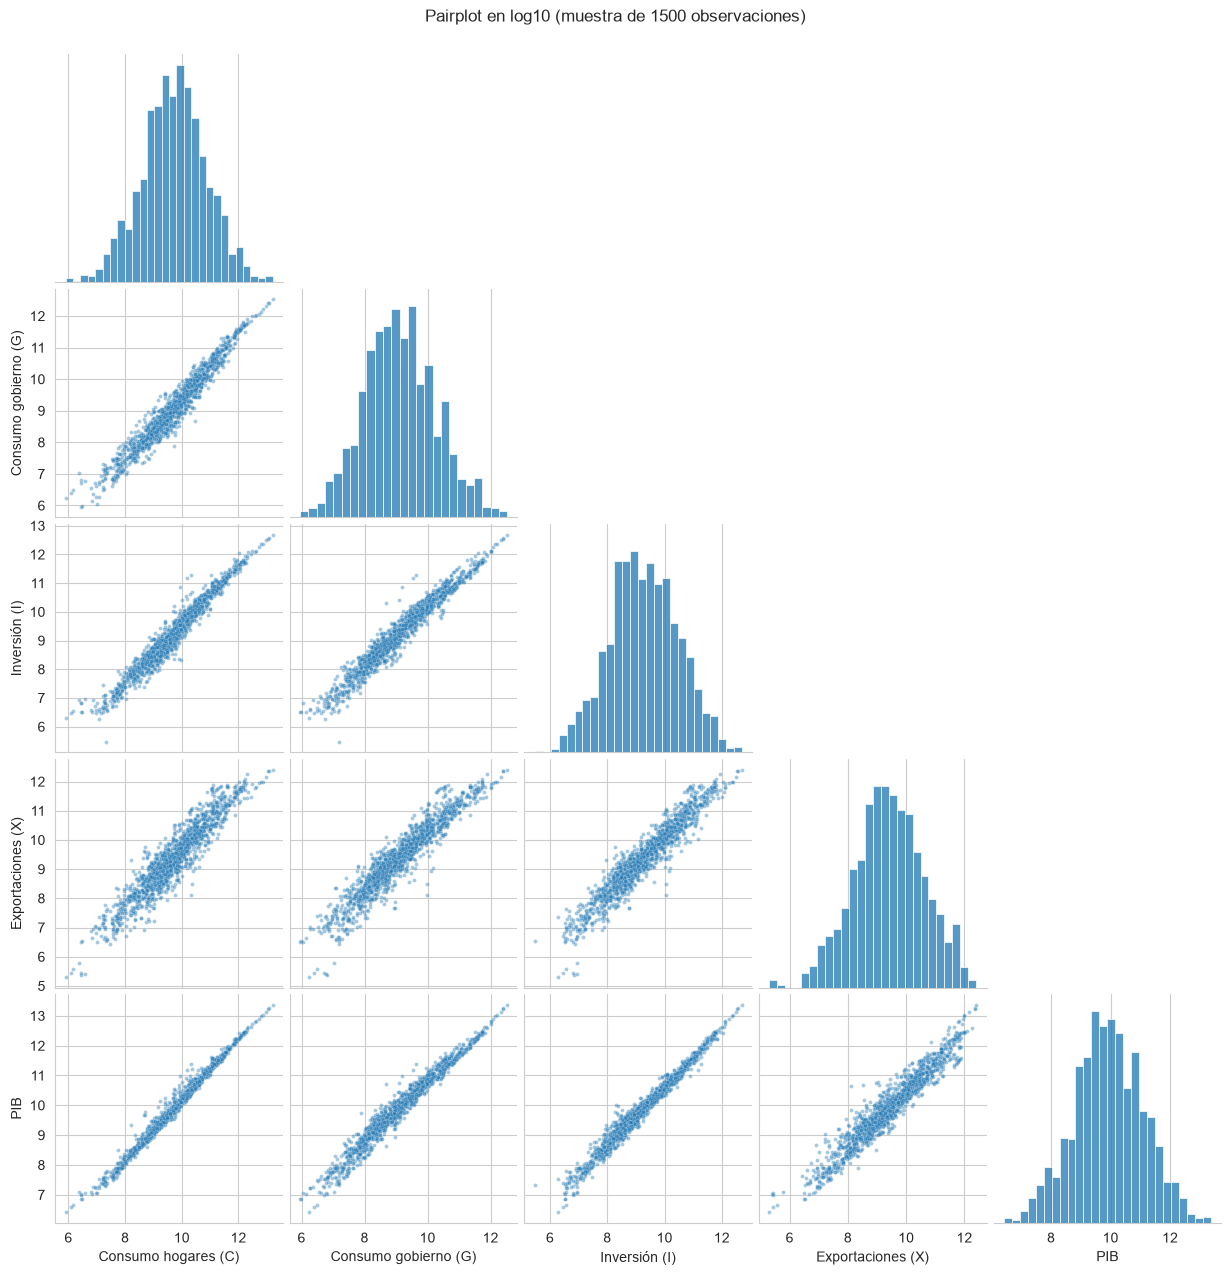

In [17]:
muestra = df[componentes[:4] + [objetivo]].dropna().sample(1500, random_state=42)
muestra_log = np.log10(muestra).rename(columns=nombres_cortos)

sns.pairplot(muestra_log, corner=True, plot_kws={"s": 8, "alpha": 0.4})
plt.suptitle("Pairplot en log10 (muestra de 1500 observaciones)", y=1.02)
plt.show()

**Qué muestra:** todas las parejas de variables en log10 y la distribución de cada una en la diagonal.

**Qué observamos:** todas las parejas forman líneas casi rectas y las distribuciones en log son parecidas a una campana. Las variables "se mueven juntas": un país grande es grande en todo.

**Decisión:** confirma la multicolinealidad que vimos en la matriz de correlación. Para el modelo usamos las variables en dólares (no en log), porque la identidad del PIB es una suma y el logaritmo la volvería no lineal.

## 6. Matrices $X$ e $y$ y división train/test

Nos quedamos con las 8 características, el objetivo, el año y el país. Eliminamos las filas con nulos y **ordenamos por año** (esto es importante para la validación que usamos en Keras).

In [18]:
df_modelo = df[features + [objetivo, "Year", "Country"]].dropna().copy()
df_modelo = df_modelo.sort_values(["Year", "Country"]).reset_index(drop=True)

print("Filas antes:", len(df))
print("Filas después de dropna:", len(df_modelo))
print(f"Se eliminó el {(1 - len(df_modelo) / len(df)):.2%} de los datos")
print("Nulos restantes:", df_modelo.isnull().sum().sum())

Filas antes: 10512
Filas después de dropna: 10254
Se eliminó el 2.45% de los datos
Nulos restantes: 0


Hacemos la división **temporal**:

- **Entrenamiento:** 1970–2012
- **Prueba:** 2013–2021 (el modelo nunca ve estos años durante el entrenamiento)

In [19]:
es_train = df_modelo["Year"] <= 2012
es_test = df_modelo["Year"] > 2012

X_train_raw = df_modelo.loc[es_train, features].values
y_train_raw = df_modelo.loc[es_train, objetivo].values
X_test_raw = df_modelo.loc[es_test, features].values
y_test_raw = df_modelo.loc[es_test, objetivo].values

print(f"Train: {X_train_raw.shape[0]} filas ({es_train.mean():.1%})  años {df_modelo.loc[es_train, 'Year'].min()}-{df_modelo.loc[es_train, 'Year'].max()}")
print(f"Test:  {X_test_raw.shape[0]} filas ({es_test.mean():.1%})  años {df_modelo.loc[es_test, 'Year'].min()}-{df_modelo.loc[es_test, 'Year'].max()}")
print()
print("X_train:", X_train_raw.shape, " y_train:", y_train_raw.shape)
print("X_test: ", X_test_raw.shape, " y_test: ", y_test_raw.shape)

Train: 8382 filas (81.7%)  años 1970-2012
Test:  1872 filas (18.3%)  años 2013-2021

X_train: (8382, 8)  y_train: (8382,)
X_test:  (1872, 8)  y_test:  (1872,)


## 7. Escalamiento

En el Lab 04 usamos min-max. Aquí probamos min-max y también estandarización (z-score):

$$x_{minmax} = \frac{x - x_{min}}{x_{max} - x_{min}} \qquad\qquad x_{z} = \frac{x - \mu}{\sigma}$$

En los dos casos, los parámetros ($min$, $max$, $\mu$, $\sigma$) se calculan **solo con el conjunto de entrenamiento** y luego se aplican iguales al de prueba. Si los calculáramos con todos los datos, el modelo tendría información de los años de prueba (data leakage).

También escalamos $y$ y guardamos sus parámetros para luego devolver las predicciones a dólares.

In [20]:
# --- min-max (lo que se uso en el lab 04) ---
X_min, X_max = X_train_raw.min(axis=0), X_train_raw.max(axis=0)
y_min, y_max = y_train_raw.min(), y_train_raw.max()

X_train_mm = (X_train_raw - X_min) / (X_max - X_min)
y_train_mm = (y_train_raw - y_min) / (y_max - y_min)

# --- z-score ---
X_media, X_std = X_train_raw.mean(axis=0), X_train_raw.std(axis=0)
y_media, y_std = y_train_raw.mean(), y_train_raw.std()

X_train = (X_train_raw - X_media) / X_std
y_train = (y_train_raw - y_media) / y_std
X_test = (X_test_raw - X_media) / X_std     # con los parametros de train
y_test = (y_test_raw - y_media) / y_std

print("Min-max  -> media de X_train por columna:", X_train_mm.mean(axis=0).round(4))
print("Z-score  -> media de X_train por columna:", X_train.mean(axis=0).round(4))
print("Z-score  -> desv. de X_train por columna:", X_train.std(axis=0).round(4))

Min-max  -> media de X_train por columna: [0.0073 0.0091 0.009  0.0148 0.0117 0.0063 0.0089 0.0164]
Z-score  -> media de X_train por columna: [ 0. -0.  0. -0. -0.  0. -0.  0.]
Z-score  -> desv. de X_train por columna: [1. 1. 1. 1. 1. 1. 1. 1.]


Con min-max, la media de cada columna queda alrededor de 0.01–0.05. Como el PIB es tan asimétrico, casi todos los países quedan apretados cerca de 0 y solo unos pocos se acercan a 1. Con z-score cada columna queda con media 0 y desviación 1.

Visualizamos el antes y el después para una variable (como en el Paso 5 del Lab 03):

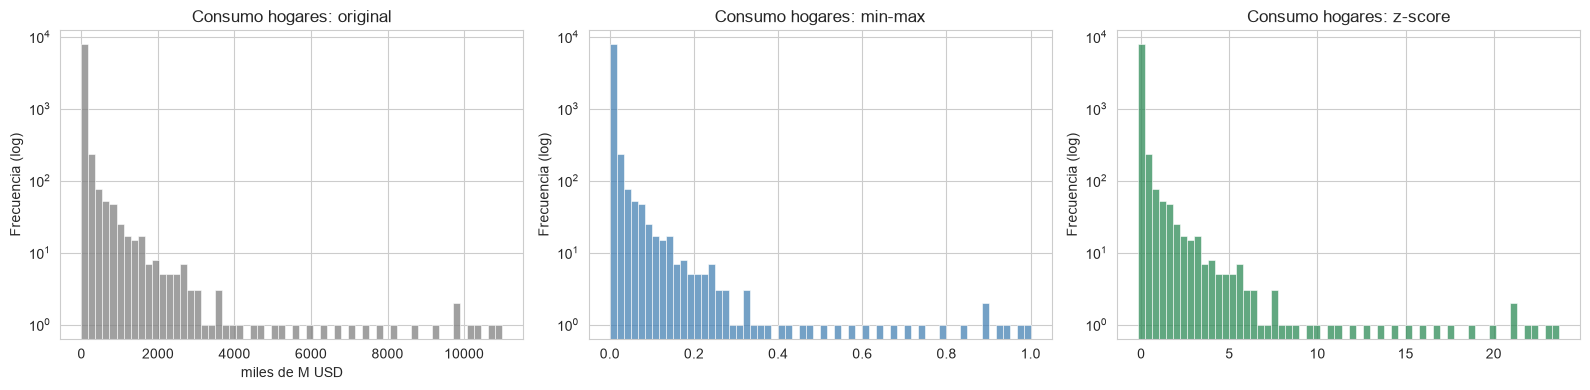

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(X_train_raw[:, 0] / 1e9, bins=60, ax=axes[0], color="gray")
axes[0].set_title("Consumo hogares: original")
axes[0].set_xlabel("miles de M USD")

sns.histplot(X_train_mm[:, 0], bins=60, ax=axes[1], color="steelblue")
axes[1].set_title("Consumo hogares: min-max")

sns.histplot(X_train[:, 0], bins=60, ax=axes[2], color="seagreen")
axes[2].set_title("Consumo hogares: z-score")

for ax in axes:
    ax.set_yscale("log")
    ax.set_ylabel("Frecuencia (log)")

plt.tight_layout()
plt.show()

El escalamiento no cambia la forma de la distribución, solo la escala. La diferencia está en el rango de los números: con min-max los valores quedan en [0, 1] pero casi todos muy cerca de 0, y con z-score quedan centrados en 0. En la sección 8 comprobamos cuál de los dos funciona mejor con el descenso de gradiente.

## 8. Perceptrón implementado con NumPy

Antes de usar Keras implementamos el perceptrón, para tener claro qué pasa en cada paso del entrenamiento.

**Forward:**
$$\mathbf{z} = X\mathbf{w} + b \qquad \hat{\mathbf{y}} = g(\mathbf{z}) = \mathbf{z}$$

**Backward (regla de la cadena):**
$$\frac{\partial \mathcal{L}}{\partial \mathbf{w}} = \frac{1}{m} X^T \left(\frac{\partial \mathcal{L}}{\partial \hat{y}} \cdot g'(z)\right) = \frac{-2}{m} X^T(\mathbf{y} - \hat{\mathbf{y}}) \qquad \frac{\partial \mathcal{L}}{\partial b} = \frac{-2}{m}\sum_{i=1}^{m}(y_i - \hat{y}_i)$$

**Actualización:**
$$\mathbf{w} \leftarrow \mathbf{w} - \alpha \frac{\partial \mathcal{L}}{\partial \mathbf{w}} \qquad b \leftarrow b - \alpha \frac{\partial \mathcal{L}}{\partial b}$$

In [ ]:
def identidad(z):
    return z

def identidad_derivada(z):
    return np.ones_like(z, dtype=float)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def mse_derivada(y_true, y_pred):
    return -2.0 * (y_true - y_pred)


class PerceptronRegresion:

    def __init__(self, n_features, learning_rate=0.01, semilla=42):
        rng = np.random.default_rng(semilla)
        self.weights = rng.standard_normal(n_features) * 0.01
        self.bias = 0.0
        self.learning_rate = learning_rate
        self.loss_history = []

    def forward(self, X):
        self.z = np.dot(X, self.weights) + self.bias
        self.y_pred = identidad(self.z)
        return self.y_pred

    def compute_loss(self, y_true, y_pred):
        return mse(y_true, y_pred)

    def backward(self, X, y_true):
        m = X.shape[0]
        dz = mse_derivada(y_true, self.y_pred) * identidad_derivada(self.z)
        self.dw = np.dot(X.T, dz) / m
        self.db = np.sum(dz) / m

    def update_parameters(self):
        self.weights = self.weights - self.learning_rate * self.dw
        self.bias = self.bias - self.learning_rate * self.db

    def train(self, X, y, epochs=100, verbose=False):
        self.loss_history = []
        for epoca in range(epochs):
            y_pred = self.forward(X)
            loss = self.compute_loss(y, y_pred)
            self.loss_history.append(loss)
            self.backward(X, y)
            self.update_parameters()
            if verbose and epoca % (epochs // 10) == 0:
                print(f"Época {epoca:5d}/{epochs} — pérdida: {loss:.6f}")
        return self.loss_history

    def predict(self, X):
        return self.forward(X)

### 8.1 ¿Qué pasa si no escalamos?

Probamos el perceptrón manual con los datos en dólares, sin escalar.

In [23]:
p_sin_escalar = PerceptronRegresion(n_features=8, learning_rate=0.01)

with np.errstate(over="ignore", invalid="ignore"):
    perdidas = p_sin_escalar.train(X_train_raw, y_train_raw, epochs=5)

for epoca, loss in enumerate(perdidas):
    print(f"Época {epoca}: pérdida = {loss:.3e}")
print("Pesos al final:", p_sin_escalar.weights)

Época 0: pérdida = 5.541e+23
Época 1: pérdida = 2.024e+67
Época 2: pérdida = 7.410e+110
Época 3: pérdida = 2.714e+154
Época 4: pérdida = 9.937e+197
Pesos al final: [9.27370465e+108 2.38961765e+108 3.45794665e+108 2.18899167e+108
 2.48831555e+108 2.64077883e+107 2.35282149e+108 6.79121421e+104]


La pérdida empieza en un número gigante (alrededor de $10^{24}$) y en pocas épocas se vuelve `inf` y luego `nan`. Los gradientes son proporcionales a $x$, que vale cientos de miles de millones, así que cada actualización salta muchísimo y los pesos se desbordan. Esto confirma que **escalar es obligatorio** para este dataset.

### 8.2 Min-max vs z-score

Entrenamos el perceptrón manual con los dos escalamientos, con el mismo learning rate y el mismo número de épocas. Como las pérdidas quedan en escalas distintas, comparamos el $R^2$ de entrenamiento en cada época ($R^2 = 1 - MSE / Var(y)$).

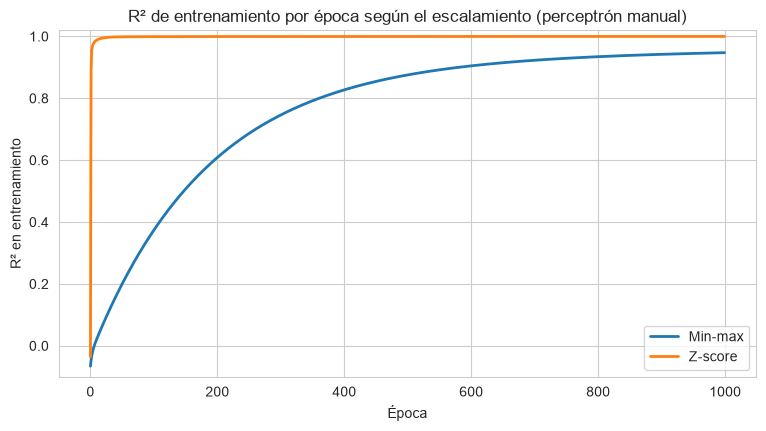

R² final con min-max: 0.9473
R² final con z-score: 0.9998


In [24]:
epocas_manual = 1000
lr_manual = 0.1

p_mm = PerceptronRegresion(n_features=8, learning_rate=lr_manual)
perdida_mm = p_mm.train(X_train_mm, y_train_mm, epochs=epocas_manual)

p_z = PerceptronRegresion(n_features=8, learning_rate=lr_manual)
perdida_z = p_z.train(X_train, y_train, epochs=epocas_manual)

r2_mm = 1 - np.array(perdida_mm) / np.var(y_train_mm)
r2_z = 1 - np.array(perdida_z) / np.var(y_train)

plt.figure(figsize=(9, 4.5))
plt.plot(r2_mm, label="Min-max", linewidth=2)
plt.plot(r2_z, label="Z-score", linewidth=2)
plt.ylim(-0.1, 1.02)
plt.title("R² de entrenamiento por época según el escalamiento (perceptrón manual)")
plt.xlabel("Época")
plt.ylabel("R² en entrenamiento")
plt.legend()
plt.show()

print(f"R² final con min-max: {r2_mm[-1]:.4f}")
print(f"R² final con z-score: {r2_z[-1]:.4f}")

Con min-max el modelo aprende mucho más lento: casi todos los valores están cerca de 0, así que los gradientes son muy pequeños. Con z-score, en pocas épocas el $R^2$ ya pasa de 0.99.

Por eso **de aquí en adelante usamos z-score**. Es un cambio respecto al Lab 04, pero allá los datos del Titanic no eran tan asimétricos como los del PIB.

### 8.3 Efecto del learning rate

Igual que en el Lab 04, comparamos varios valores de $\alpha$ en una misma gráfica.

lr = 0.001  pérdida final: 0.0351598
lr = 0.01   pérdida final: 0.00279966
lr = 0.1    pérdida final: 0.000474363
lr = 0.2    pérdida final: 3.39159e+106


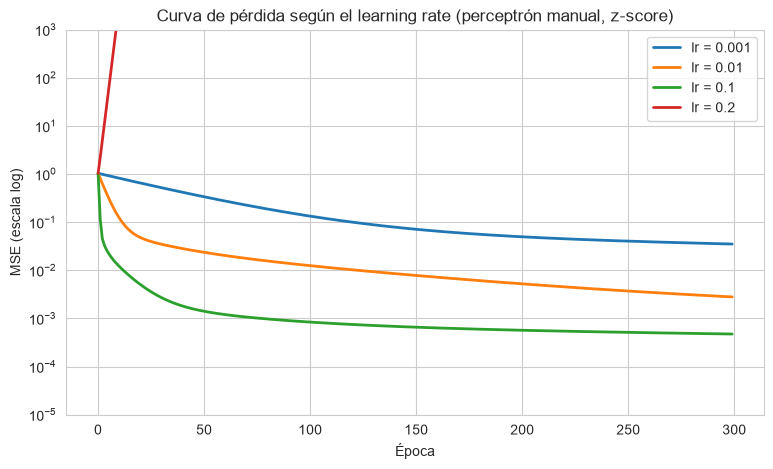

In [25]:
learning_rates = [0.001, 0.01, 0.1, 0.2]

plt.figure(figsize=(9, 5))
for lr in learning_rates:
    p_lr = PerceptronRegresion(n_features=8, learning_rate=lr)
    with np.errstate(over="ignore", invalid="ignore"):
        hist = p_lr.train(X_train, y_train, epochs=300)
    plt.plot(hist, label=f"lr = {lr}", linewidth=2)
    print(f"lr = {lr:<6} pérdida final: {hist[-1]:.6g}")

plt.yscale("log")
plt.ylim(1e-5, 1e3)
plt.title("Curva de pérdida según el learning rate (perceptrón manual, z-score)")
plt.xlabel("Época")
plt.ylabel("MSE (escala log)")
plt.legend()
plt.show()

- **lr = 0.001:** baja muy despacio y en 300 épocas no llega al mínimo.
- **lr = 0.01:** mejora, pero sigue lento.
- **lr = 0.1:** es el que mejor funciona: baja rápido y de forma estable.
- **lr = 0.2:** la pérdida **crece** en vez de bajar. El paso es tan grande que el modelo se pasa del mínimo en cada actualización y diverge (*overshooting*). Como las variables están tan correlacionadas, la superficie de pérdida es muy "empinada" en una dirección y no tolera pasos grandes.

### 8.4 Pesos del perceptrón manual

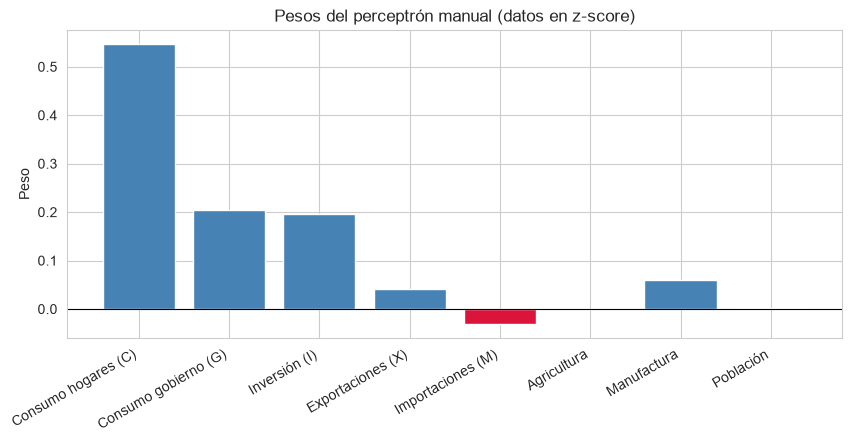

Consumo hogares (C)    +0.5471
Consumo gobierno (G)   +0.2047
Inversión (I)          +0.1966
Exportaciones (X)      +0.0420
Importaciones (M)      -0.0309
Agricultura            -0.0007
Manufactura            +0.0602
Población              +0.0010
Sesgo                  -0.0000


In [26]:
etiquetas = [nombres_cortos[f] for f in features]

plt.figure(figsize=(10, 4))
colores = ["crimson" if w < 0 else "steelblue" for w in p_z.weights]
plt.bar(etiquetas, p_z.weights, color=colores)
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=30, ha="right")
plt.title("Pesos del perceptrón manual (datos en z-score)")
plt.ylabel("Peso")
plt.show()

for nombre, w in zip(etiquetas, p_z.weights):
    print(f"{nombre:<22} {w:+.4f}")
print(f"{'Sesgo':<22} {p_z.bias:+.4f}")

Ya se ve el patrón esperado: el peso de las importaciones es negativo y los de consumo, inversión y exportaciones son positivos. En la sección 13 pasamos los pesos a dólares para compararlos con la identidad.

## 9. Perceptrón con Keras

Ahora construimos el mismo modelo con Keras: **una sola capa `Dense` con 1 neurona** que conecta las 8 entradas con la salida. Usamos `keras.Input` para definir la forma de la entrada (en el Lab 04 Keras mostraba una advertencia cuando se pasaba `input_shape` directamente a `Dense`).

In [27]:
n_features = X_train.shape[1]

modelo = keras.Sequential([
    keras.Input(shape=(n_features,)),
    layers.Dense(units=1, activation="linear", name="neurona")
], name="perceptron_pib")

modelo.summary()

Model: "perceptron_pib"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ neurona (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

El modelo tiene **9 parámetros**: 8 pesos (uno por característica) y 1 sesgo. No hay capas ocultas.

### Compilación

- **Optimizador:** `SGD` (descenso de gradiente estocástico) con `learning_rate=0.01` y `momentum=0.9`. El momentum acumula la dirección de los pasos anteriores:
  $$v \leftarrow \beta v - \alpha \nabla \mathcal{L} \qquad w \leftarrow w + v$$
  Eso ayuda a avanzar en las direcciones "planas" que aparecen cuando las variables están correlacionadas. Usamos un lr más bajo que en el manual porque aquí actualizamos con lotes pequeños de 64 filas, que son más ruidosos que el lote completo.
- **Pérdida:** `mse`, como definimos en el diseño.
- **Métrica:** `mae`.

In [28]:
modelo.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    loss="mse",
    metrics=["mae"]
)

## 10. Entrenamiento y actualización de los pesos

### 10.1 Un paso de descenso de gradiente, a mano y con Keras

Para ver exactamente cómo se actualizan los pesos, tomamos un lote de 64 filas y hacemos **un solo paso** de descenso de gradiente de dos formas:

1. a mano con NumPy, usando las fórmulas de la sección 8;
2. con Keras (`train_on_batch`), partiendo de los mismos pesos iniciales.

Si las dos dan lo mismo, sabemos que Keras hace exactamente lo que implementamos. Para que la comparación sea justa usamos SGD sin momentum.

In [29]:
lote_X = X_train[:64].astype("float32")
lote_y = y_train[:64].astype("float32").reshape(-1, 1)
alpha = 0.01

# modelo auxiliar con los mismos pesos iniciales que "modelo"
modelo_paso = keras.Sequential([
    keras.Input(shape=(n_features,)),
    layers.Dense(1, activation="linear", name="neurona")
])
modelo_paso.get_layer("neurona").set_weights(modelo.get_layer("neurona").get_weights())
modelo_paso.compile(optimizer=keras.optimizers.SGD(learning_rate=alpha), loss="mse")

w0, b0 = modelo_paso.get_layer("neurona").get_weights()
w0 = w0.flatten()

# 1) a mano
y_hat = lote_X @ w0 + b0[0]
error = lote_y.flatten() - y_hat
grad_w = -2 / len(lote_X) * lote_X.T @ error
grad_b = -2 / len(lote_X) * error.sum()
w_manual = w0 - alpha * grad_w
b_manual = b0[0] - alpha * grad_b

# 2) con keras
modelo_paso.train_on_batch(lote_X, lote_y)
w_keras, b_keras = modelo_paso.get_layer("neurona").get_weights()

tabla_paso = pd.DataFrame({
    "peso inicial": np.append(w0, b0[0]),
    "gradiente": np.append(grad_w, grad_b),
    "peso nuevo (manual)": np.append(w_manual, b_manual),
    "peso nuevo (Keras)": np.append(w_keras.flatten(), b_keras[0]),
}, index=etiquetas + ["Sesgo"])

print("¿Coinciden?", np.allclose(tabla_paso["peso nuevo (manual)"], tabla_paso["peso nuevo (Keras)"], atol=1e-5))
tabla_paso.round(6)

¿Coinciden? True


,peso inicial,gradiente,peso nuevo (manual),peso nuevo (Keras)
Consumo hogares (C),0.584920,0.014133,0.584779,0.584779
Consumo gobierno (G),0.265571,0.016296,0.265408,0.265408
Inversión (I),-0.230724,0.015155,-0.230876,-0.230876
Exportaciones (X),0.734830,0.024272,0.734587,0.734587
Importaciones (M),-0.689023,0.022399,-0.689247,-0.689247
Agricultura,0.248758,0.014372,0.248614,0.248614
Manufactura,0.768323,0.014014,0.768183,0.768183
Población,-0.542297,-0.019800,-0.542099,-0.542099
Sesgo,0.000000,-0.103170,0.001032,0.001032


Los pesos nuevos calculados a mano y los de Keras coinciden (las diferencias son del orden de la precisión de `float32`). Cada peso se movió en sentido contrario a su gradiente: si el gradiente es positivo el peso baja, y si es negativo sube. Keras hace lo mismo que nuestra implementación, solo que calcula las derivadas automáticamente.

### 10.2 Entrenamiento completo

Para registrar los pesos en cada época creamos un *callback*. Un callback es una clase de Keras con métodos que se ejecutan en ciertos momentos del entrenamiento; en este caso usamos `on_epoch_end`, que se llama al final de cada época. Además, cada 10 épocas imprime la pérdida y algunos pesos.

Usamos `validation_split=0.1`. Keras toma el **último 10 %** de los datos de entrenamiento como validación, y como ordenamos por año, esos son los años más recientes del entrenamiento (aprox. 2009–2012). Así la validación también es temporal.

In [30]:
class HistorialPesos(keras.callbacks.Callback):
    # guarda los pesos y el sesgo de la neurona al final de cada epoca

    def on_train_begin(self, logs=None):
        self.pesos = []
        self.sesgos = []

    def on_epoch_end(self, epoch, logs=None):
        w, b = self.model.get_layer("neurona").get_weights()
        self.pesos.append(w.flatten().copy())
        self.sesgos.append(float(b[0]))

        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f"Época {epoch + 1:3d} | loss {logs['loss']:.6f} | val_loss {logs['val_loss']:.6f} | "
                  f"w_C {w[0, 0]:+.3f}  w_I {w[2, 0]:+.3f}  w_X {w[3, 0]:+.3f}  w_M {w[4, 0]:+.3f}  b {b[0]:+.4f}")


historial_pesos = HistorialPesos()
pesos_iniciales = modelo.get_layer("neurona").get_weights()[0].flatten()

history = modelo.fit(
    X_train,
    y_train.reshape(-1, 1),
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[historial_pesos],
    verbose=0
)

Época   1 | loss 0.130555 | val_loss 0.214076 | w_C +0.805  w_I -0.303  w_X +0.474  w_M -0.589  b -0.0156
Época  10 | loss 0.003728 | val_loss 0.029220 | w_C +0.788  w_I +0.095  w_X +0.306  w_M -0.345  b -0.0051
Época  20 | loss 0.000820 | val_loss 0.007871 | w_C +0.708  w_I +0.213  w_X +0.256  w_M -0.281  b -0.0025
Época  30 | loss 0.000276 | val_loss 0.003268 | w_C +0.673  w_I +0.243  w_X +0.229  w_M -0.248  b -0.0015
Época  40 | loss 0.000134 | val_loss 0.001813 | w_C +0.657  w_I +0.250  w_X +0.212  w_M -0.228  b -0.0011
Época  50 | loss 0.000086 | val_loss 0.001214 | w_C +0.649  w_I +0.251  w_X +0.201  w_M -0.215  b -0.0008
Época  60 | loss 0.000067 | val_loss 0.000920 | w_C +0.645  w_I +0.251  w_X +0.194  w_M -0.207  b -0.0007
Época  70 | loss 0.000058 | val_loss 0.000759 | w_C +0.642  w_I +0.250  w_X +0.189  w_M -0.201  b -0.0006
Época  80 | loss 0.000053 | val_loss 0.000665 | w_C +0.640  w_I +0.249  w_X +0.186  w_M -0.197  b -0.0005
Época  90 | loss 0.000051 | val_loss 0.000606 

In [31]:
pesos_por_epoca = np.array(historial_pesos.pesos)
epocas = np.arange(1, len(pesos_por_epoca) + 1)

tabla_pesos = pd.DataFrame(pesos_por_epoca, columns=etiquetas, index=epocas)
tabla_pesos["Sesgo"] = historial_pesos.sesgos
tabla_pesos["loss"] = history.history["loss"]
tabla_pesos.index.name = "Época"

tabla_pesos.loc[[1, 5, 10, 25, 50, 75, 100]].round(4)

,Consumo hogares (C),Consumo gobierno (G),Inversión (I),Exportaciones (X),Importaciones (M),Agricultura,Manufactura,Población,Sesgo,loss
Época,,,,,,,,,,
1,0.8051,0.2496,-0.3027,0.4744,-0.5888,0.2639,0.3073,0.0402,-0.0156,0.1306
5,0.8574,0.1859,-0.0704,0.3528,-0.4160,0.1737,0.0788,0.0215,-0.0080,0.0102
10,0.7884,0.1411,0.0947,0.3059,-0.3454,0.1017,0.0243,0.0152,-0.0051,0.0037
25,0.6873,0.1461,0.2330,0.2406,-0.2624,0.0313,-0.0190,0.0085,-0.0019,0.0005
50,0.6493,0.1554,0.2513,0.2009,-0.2152,0.0118,-0.0135,0.0047,-0.0008,0.0001
75,0.6408,0.1568,0.2493,0.1872,-0.1989,0.0082,-0.0069,0.0034,-0.0005,0.0001
100,0.6380,0.1571,0.2480,0.1823,-0.1930,0.0070,-0.0042,0.0029,-0.0004,0.0000


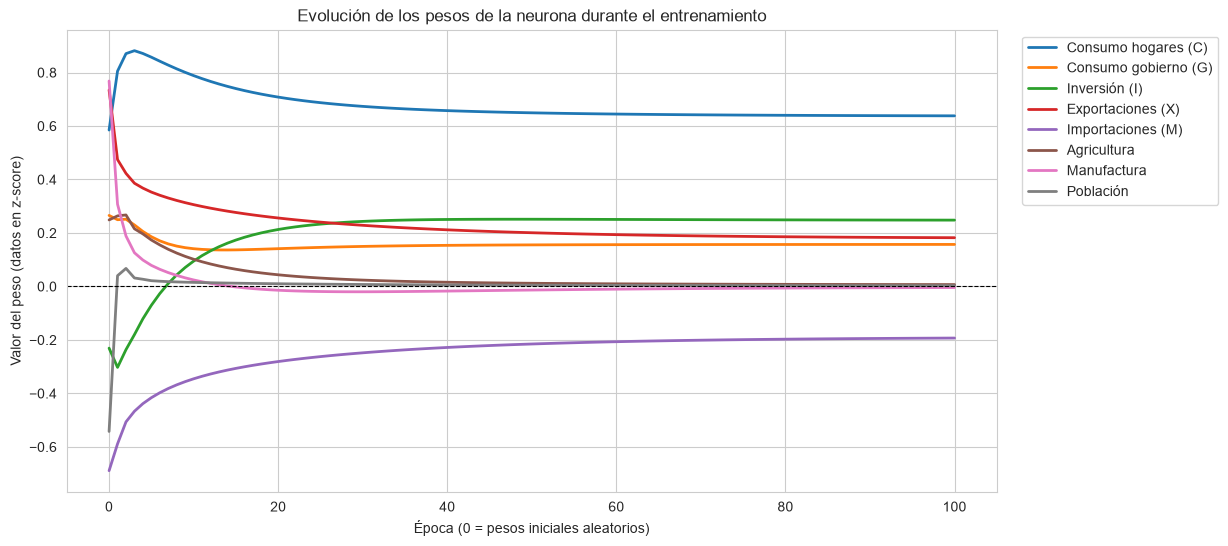

In [32]:
plt.figure(figsize=(12, 6))
for j, nombre in enumerate(etiquetas):
    trayectoria = np.concatenate([[pesos_iniciales[j]], pesos_por_epoca[:, j]])
    plt.plot(np.arange(0, len(trayectoria)), trayectoria, label=nombre, linewidth=2)

plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Evolución de los pesos de la neurona durante el entrenamiento")
plt.xlabel("Época (0 = pesos iniciales aleatorios)")
plt.ylabel("Valor del peso (datos en z-score)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

En la época 0 los pesos son aleatorios (Keras los inicializa con *Glorot uniform*). En las primeras 5 épocas cambian mucho, porque los gradientes son grandes, y después se mueven cada vez menos. Los pesos de agricultura, manufactura y población se van a 0 casi de inmediato. El de las importaciones queda negativo y es el que más tarda en estabilizarse: sigue subiendo poco a poco hasta el final, al mismo tiempo que baja el de las exportaciones. Como exportaciones e importaciones tienen una correlación de 0.98, el modelo puede subir una y bajar la otra casi sin cambiar la pérdida, y por eso esa pareja converge lento. Es el efecto de la multicolinealidad que vimos en el EDA.

## 11. Curva de pérdida

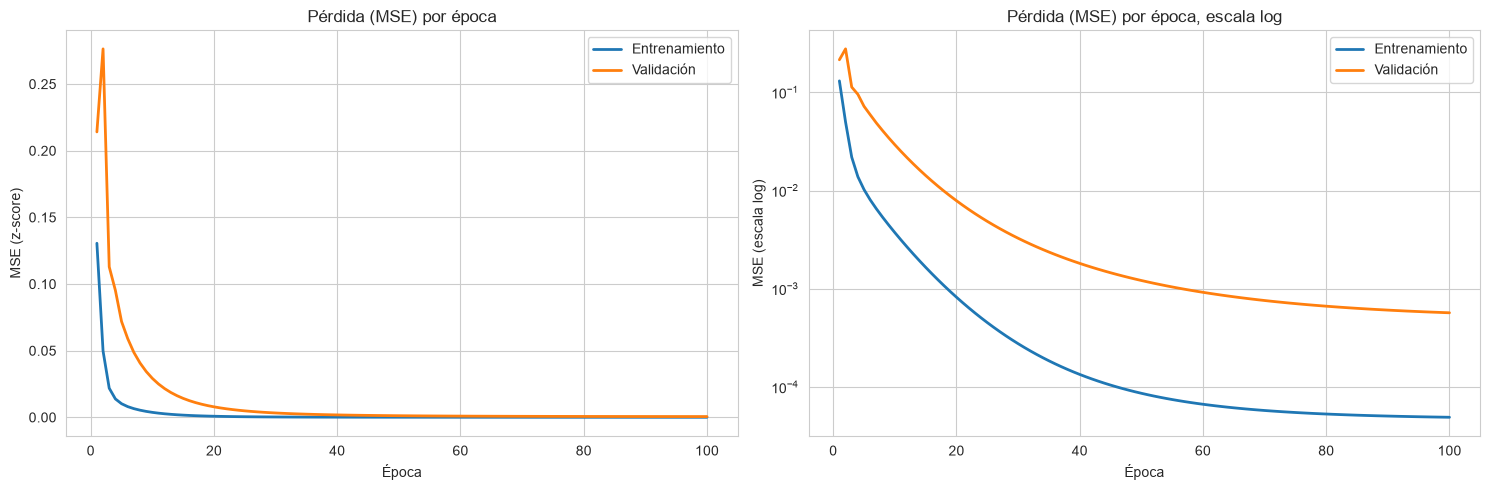

Pérdida época 1:   0.130555
Pérdida época 100: 0.000049
Validación época 100: 0.000570


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(epocas, history.history["loss"], label="Entrenamiento", linewidth=2)
axes[0].plot(epocas, history.history["val_loss"], label="Validación", linewidth=2)
axes[0].set_title("Pérdida (MSE) por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("MSE (z-score)")
axes[0].legend()

axes[1].plot(epocas, history.history["loss"], label="Entrenamiento", linewidth=2)
axes[1].plot(epocas, history.history["val_loss"], label="Validación", linewidth=2)
axes[1].set_yscale("log")
axes[1].set_title("Pérdida (MSE) por época, escala log")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("MSE (escala log)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Pérdida época 1:   {history.history['loss'][0]:.6f}")
print(f"Pérdida época 100: {history.history['loss'][-1]:.6f}")
print(f"Validación época 100: {history.history['val_loss'][-1]:.6f}")

La pérdida cae muchísimo en las primeras épocas: en la escala lineal casi todo el descenso ocurre en las 3 primeras. Por eso agregamos la escala logarítmica, donde se ve que después sigue bajando más despacio.

En la escala log aparecen algunos **picos**. Son normales en el descenso de gradiente estocástico: cada actualización usa solo 64 filas, y cuando un lote trae observaciones extremas (Estados Unidos o China, que en z-score valen más de 20) el gradiente de ese lote es muy grande y el modelo se mueve de más. En las épocas siguientes la pérdida vuelve a bajar. Probamos con un learning rate más bajo y la curva queda más suave, pero los pesos terminan más lejos de la solución óptima (ver sección 13), así que preferimos dejar 0.01.

La curva de validación (años más recientes del entrenamiento, que el modelo no usa para actualizar los pesos) sigue a la de entrenamiento y no se separa hacia arriba con las épocas. Es decir, **no hay sobreajuste**, lo cual era de esperar en un modelo con solo 9 parámetros. Que la validación quede un poco por encima del entrenamiento también es lógico: son años con economías más grandes.

## 12. Evaluación en el conjunto de prueba (2013–2021)

Evaluamos con `evaluate` en la escala z-score y después pasamos las predicciones a dólares para calcular métricas fáciles de interpretar:

- $R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$
- $MAE = \frac{1}{m}\sum |y_i - \hat{y}_i|$
- $RMSE = \sqrt{\frac{1}{m}\sum (y_i - \hat{y}_i)^2}$
- Error porcentual mediano: la mediana de $|y_i - \hat{y}_i| / y_i$

In [34]:
loss_test, mae_test = modelo.evaluate(X_test, y_test.reshape(-1, 1), verbose=0)
print(f"MSE en test (z-score): {loss_test:.6f}")
print(f"MAE en test (z-score): {mae_test:.6f}")

# predicciones en dolares
y_pred_test = modelo.predict(X_test, verbose=0).flatten() * y_std + y_media
y_pred_train = modelo.predict(X_train, verbose=0).flatten() * y_std + y_media

def metricas(y_real, y_pred):
    r2 = 1 - np.sum((y_real - y_pred) ** 2) / np.sum((y_real - y_real.mean()) ** 2)
    mae = np.mean(np.abs(y_real - y_pred))
    rmse = np.sqrt(np.mean((y_real - y_pred) ** 2))
    error_pct = np.median(np.abs(y_real - y_pred) / y_real) * 100
    return r2, mae, rmse, error_pct

resultados = pd.DataFrame(
    [metricas(y_train_raw, y_pred_train), metricas(y_test_raw, y_pred_test)],
    index=["Entrenamiento (1970-2012)", "Prueba (2013-2021)"],
    columns=["R²", "MAE (USD)", "RMSE (USD)", "Error % mediano"]
)
resultados.style.format({"R²": "{:.5f}", "MAE (USD)": "{:,.0f}", "RMSE (USD)": "{:,.0f}", "Error % mediano": "{:.2f}%"})

MSE en test (z-score): 0.001466
MAE en test (z-score): 0.009010


,R²,MAE (USD),RMSE (USD),Error % mediano
Entrenamiento (1970-2012),0.99984,"3,534,240,698","9,135,781,292",39.10%
Prueba (2013-2021),0.99974,"6,593,598,078","28,022,365,161",6.99%


### Gráfica de predicciones vs valores reales

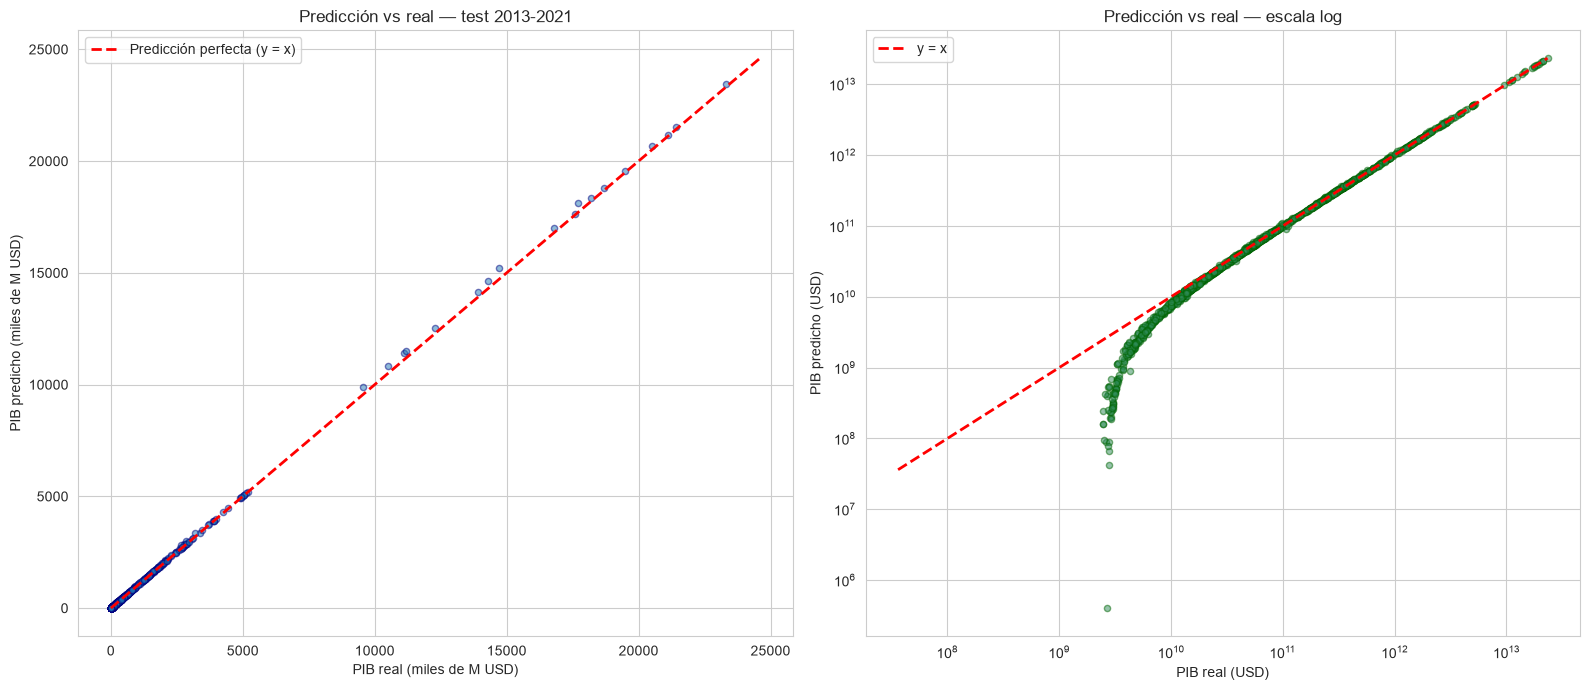

Predicciones negativas o cero: 324 de 1872


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# escala lineal
axes[0].scatter(y_test_raw / 1e9, y_pred_test / 1e9, alpha=0.5, s=20, edgecolor="navy")
lim = max(y_test_raw.max(), y_pred_test.max()) / 1e9 * 1.05
axes[0].plot([0, lim], [0, lim], "r--", linewidth=2, label="Predicción perfecta (y = x)")
axes[0].set_title("Predicción vs real — test 2013-2021")
axes[0].set_xlabel("PIB real (miles de M USD)")
axes[0].set_ylabel("PIB predicho (miles de M USD)")
axes[0].legend()

# escala log, para ver los paises pequeños
positivos = y_pred_test > 0
axes[1].scatter(y_test_raw[positivos], y_pred_test[positivos], alpha=0.5, s=20, color="seagreen", edgecolor="darkgreen")
axes[1].plot([y_test_raw.min(), y_test_raw.max()], [y_test_raw.min(), y_test_raw.max()], "r--", linewidth=2, label="y = x")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Predicción vs real — escala log")
axes[1].set_xlabel("PIB real (USD)")
axes[1].set_ylabel("PIB predicho (USD)")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Predicciones negativas o cero:", (~positivos).sum(), "de", len(y_pred_test))

En la gráfica lineal los puntos quedan sobre la diagonal, incluyendo las economías más grandes (Estados Unidos, China), que tienen valores por encima de lo que el modelo vio en entrenamiento. La gráfica en escala log muestra lo que pasa con los países pequeños, que en la escala lineal quedan amontonados en el origen. Desde unos mil millones de USD hacia arriba, los puntos siguen pegados a la línea. Por debajo de ese valor el modelo **sobreestima**: las predicciones se quedan alrededor de unos cientos de millones aunque el PIB real sea mucho menor. Esto pasa porque el sesgo y las pequeñas desviaciones de los pesos valen poco en dólares para un país grande, pero son comparables al PIB completo de un país muy pequeño (por ejemplo, Tuvalu o Nauru).

### Residuos

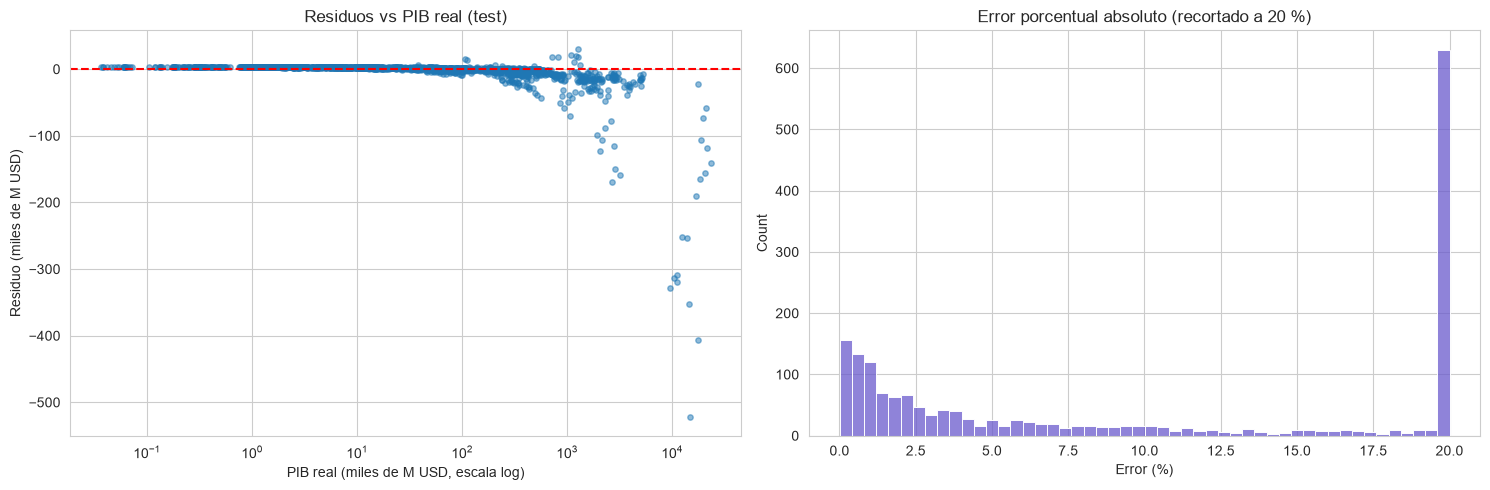

Observaciones con error < 1 %: 18.4%
Observaciones con error < 5 %: 44.3%


In [36]:
residuos = y_test_raw - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_test_raw / 1e9, residuos / 1e9, alpha=0.5, s=15)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xscale("log")
axes[0].set_title("Residuos vs PIB real (test)")
axes[0].set_xlabel("PIB real (miles de M USD, escala log)")
axes[0].set_ylabel("Residuo (miles de M USD)")

error_pct = np.abs(residuos) / y_test_raw * 100
sns.histplot(np.clip(error_pct, 0, 20), bins=50, ax=axes[1], color="slateblue")
axes[1].set_title("Error porcentual absoluto (recortado a 20 %)")
axes[1].set_xlabel("Error (%)")

plt.tight_layout()
plt.show()

print(f"Observaciones con error < 1 %: {(error_pct < 1).mean():.1%}")
print(f"Observaciones con error < 5 %: {(error_pct < 5).mean():.1%}")

Los residuos están centrados en 0, sin una tendencia clara hacia arriba o hacia abajo, lo que indica que el modelo no se equivoca de forma sistemática. Su tamaño en dólares crece con el tamaño del país (*heterocedasticidad*): equivocarse en un 1 % con Estados Unidos son cientos de miles de millones, mientras que con un país pequeño son unos pocos millones. Por eso, además del MAE en dólares, reportamos el error porcentual.

### Predicciones para algunos países en 2019

In [37]:
resultados_test = df_modelo.loc[es_test, ["Country", "Year", objetivo]].copy()
resultados_test["PIB predicho"] = y_pred_test
resultados_test["Error %"] = (resultados_test["PIB predicho"] - resultados_test[objetivo]) / resultados_test[objetivo] * 100

paises_muestra = ["United States", "China", "Germany", "Japan", "India", "Brazil", "Mexico", "Colombia", "Chile", "South Africa"]
tabla_2019 = resultados_test[(resultados_test["Year"] == 2019) & (resultados_test["Country"].isin(paises_muestra))].copy()
tabla_2019["PIB real (mil M USD)"] = tabla_2019[objetivo] / 1e9
tabla_2019["PIB predicho (mil M USD)"] = tabla_2019["PIB predicho"] / 1e9

tabla_2019[["Country", "PIB real (mil M USD)", "PIB predicho (mil M USD)", "Error %"]].sort_values(
    "PIB real (mil M USD)", ascending=False).round(2)

,Country,PIB real (mil M USD),PIB predicho (mil M USD),Error %
9828,United States,21400.0,21518.92,0.56
9670,China,14300.0,14652.64,2.47
9724,Japan,5120.0,5132.78,0.25
9703,Germany,3890.0,3912.02,0.57
9716,India,2850.0,3000.46,5.28
9656,Brazil,1880.0,1911.69,1.69
9750,Mexico,1270.0,1251.96,-1.42
9801,South Africa,389.0,389.69,0.18
9672,Colombia,323.0,327.02,1.24
9669,Chile,279.0,280.74,0.62


## 13. ¿Qué aprendió el perceptrón?

Los pesos de Keras están en escala z-score. Para compararlos con la identidad del PIB hay que pasarlos a dólares. Si $\hat{y}_z = \sum w_j x_{z,j} + b$, con $x_{z,j} = (x_j - \mu_j)/\sigma_j$ y $y = \mu_y + \sigma_y \hat{y}_z$, entonces:

$$w_j^{USD} = w_j \cdot \frac{\sigma_y}{\sigma_j}$$

Un peso de $w_j^{USD} = 1$ significa que si esa variable sube 1 dólar, el PIB predicho sube 1 dólar.

Como referencia, calculamos también la solución **exacta** de mínimos cuadrados con NumPy (`np.linalg.lstsq`), que es el mínimo global de la MSE que el descenso de gradiente intenta alcanzar.

In [38]:
w_keras, b_keras = modelo.get_layer("neurona").get_weights()
w_keras = w_keras.flatten()
w_keras_usd = w_keras * y_std / X_std

w_manual_usd = p_z.weights * y_std / X_std

# solucion exacta de minimos cuadrados (con columna de unos para el sesgo)
X_con_sesgo = np.c_[X_train, np.ones(len(X_train))]
w_exacto, *_ = np.linalg.lstsq(X_con_sesgo, y_train, rcond=None)
w_exacto_usd = w_exacto[:-1] * y_std / X_std

teoria = [1, 1, 1, 1, -1, 0, 0, 0]

tabla_comparacion = pd.DataFrame({
    "Teoría (identidad)": teoria,
    "Mínimos cuadrados (NumPy)": w_exacto_usd,
    "Perceptrón manual": w_manual_usd,
    "Perceptrón Keras": w_keras_usd,
}, index=etiquetas)

tabla_comparacion.round(3)

,Teoría (identidad),Mínimos cuadrados (NumPy),Perceptrón manual,Perceptrón Keras
Consumo hogares (C),1,1.006,0.869,1.013
Consumo gobierno (G),1,0.971,1.261,0.968
Inversión (I),1,1.017,0.808,1.020
Exportaciones (X),1,1.021,0.248,1.078
Importaciones (M),-1,-1.021,-0.172,-1.077
Agricultura,0,0.055,-0.024,0.232
Manufactura,0,-0.017,0.356,-0.025
Población,0,-13.617,8.758,24.967


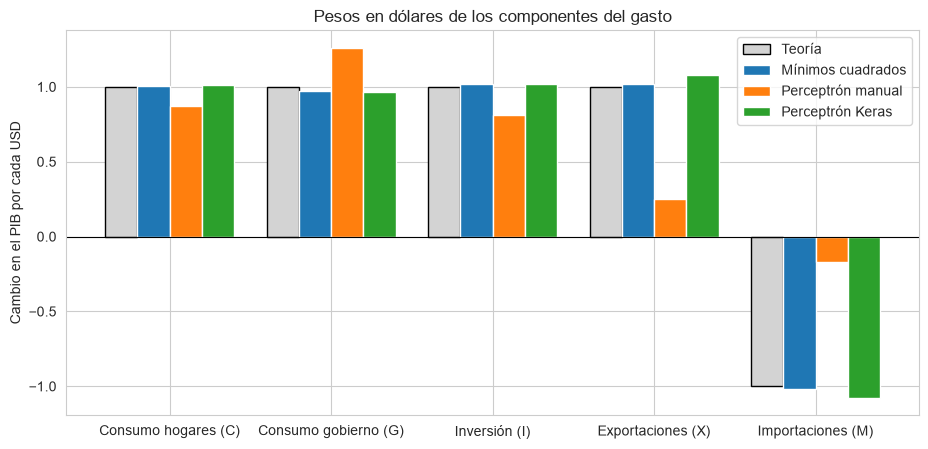

Peso de la población en USD por persona:
  mínimos cuadrados: -13.62   Keras: +24.97


In [39]:
pos = np.arange(5)
ancho = 0.2

plt.figure(figsize=(11, 5))
plt.bar(pos - 1.5 * ancho, teoria[:5], ancho, label="Teoría", color="lightgray", edgecolor="black")
plt.bar(pos - 0.5 * ancho, w_exacto_usd[:5], ancho, label="Mínimos cuadrados")
plt.bar(pos + 0.5 * ancho, w_manual_usd[:5], ancho, label="Perceptrón manual")
plt.bar(pos + 1.5 * ancho, w_keras_usd[:5], ancho, label="Perceptrón Keras")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(pos, etiquetas[:5])
plt.title("Pesos en dólares de los componentes del gasto")
plt.ylabel("Cambio en el PIB por cada USD")
plt.legend()
plt.show()

print("Peso de la población en USD por persona:")
print(f"  mínimos cuadrados: {w_exacto_usd[7]:+.2f}   Keras: {w_keras_usd[7]:+.2f}")

**Qué vemos:**

- La solución de mínimos cuadrados queda prácticamente en $+1, +1, +1, +1, -1$. Esto confirma que la identidad del PIB está en los datos y que el mínimo de la MSE corresponde a ella.
- El perceptrón de Keras llega muy cerca de esos valores (todos los pesos de $C, G, I, X, M$ quedan a menos de unos 0.1 de la teoría) usando solo descenso de gradiente, sin que nunca le dijéramos la fórmula. En particular, **descubre que las importaciones restan** al PIB.
- El perceptrón manual acierta los signos y se acerca en consumo e inversión, pero se queda corto en exportaciones (≈ 0.25) e importaciones (≈ −0.17), y compensa con un peso de manufactura de ≈ 0.36. La razón es la misma de la sección 10.2: exportaciones e importaciones tienen correlación 0.98, así que la dirección "subir $X$ y bajar $M$ a la vez" casi no cambia la pérdida. El descenso de gradiente por lote completo, sin momentum, avanza muy despacio en esa dirección y 1000 épocas no alcanzan. Keras, con momentum y mini-lotes, sí logra avanzar.
- La agricultura y la manufactura terminan con pesos pequeños en Keras. Su información ya está contenida en los componentes del gasto.
- El peso de la población, expresado por persona, es de unos pocos dólares. Frente a PIB de miles de millones, eso es prácticamente 0.

### Comparación de curvas: manual vs Keras

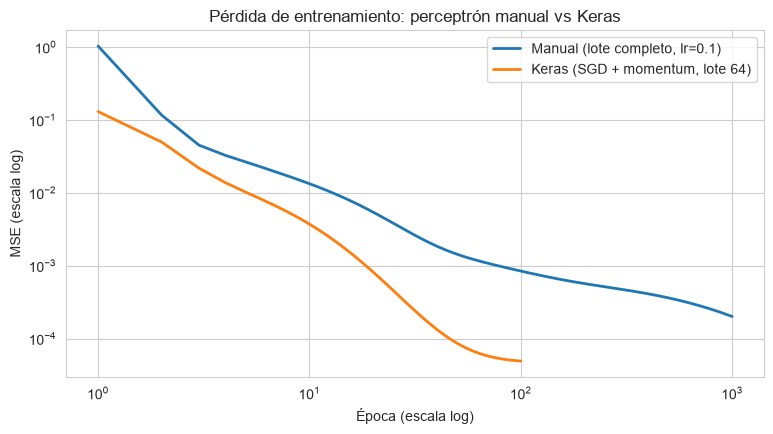

R² en test — manual: 0.99966   Keras: 0.99974


In [40]:
plt.figure(figsize=(9, 4.5))
plt.plot(np.arange(1, epocas_manual + 1), perdida_z, label="Manual (lote completo, lr=0.1)", linewidth=2)
plt.plot(epocas, history.history["loss"], label="Keras (SGD + momentum, lote 64)", linewidth=2)
plt.yscale("log")
plt.xscale("log")
plt.title("Pérdida de entrenamiento: perceptrón manual vs Keras")
plt.xlabel("Época (escala log)")
plt.ylabel("MSE (escala log)")
plt.legend()
plt.show()

r2_manual_test = metricas(y_test_raw, p_z.predict(X_test) * y_std + y_media)[0]
print(f"R² en test — manual: {r2_manual_test:.5f}   Keras: {resultados.iloc[1, 0]:.5f}")

Keras llega a una pérdida menor en muchas menos épocas. En cada época hace unas 118 actualizaciones (una por lote de 64), mientras que el manual hace solo una, y el momentum le permite avanzar más rápido en las direcciones planas. Aun así, los dos modelos tienen un $R^2$ de prueba muy alto. Esto confirma lo que decíamos: aunque los pesos del manual son bastante distintos, las predicciones casi no cambian, porque se diferencian justo en las direcciones "planas" de la pérdida.

**¿Qué hace Keras automáticamente?** Calcula los gradientes (diferenciación automática), parte los datos en lotes y los mezcla en cada época, inicializa los pesos y lleva el registro de las métricas. **¿Qué se pierde?** No vemos las derivadas de forma explícita; por eso fue útil comprobar en la sección 10.1 que un paso de Keras es igual a uno hecho a mano.

## 14. Limitaciones y conclusiones

### Limitaciones

1. **El problema es casi una identidad contable.** El modelo funciona tan bien porque el PIB *es* la suma de sus componentes del gasto. No sirve para pronosticar el PIB del próximo año, porque para usarlo hay que conocer el consumo, la inversión, etc. del mismo año, y esas cifras se publican junto con el PIB.
2. **Solo es lineal.** Un perceptrón simple no puede capturar efectos no lineales. Aquí no hizo falta, pero si quisiéramos predecir el PIB con variables como población o tipo de cambio, la relación no sería lineal y el modelo fallaría (como pasó con los pingüinos en el Lab 04).
3. **Multicolinealidad.** Como las entradas están tan correlacionadas, los pesos individuales tardan en estabilizarse y dependen del optimizador y del número de épocas, aunque las predicciones sean buenas.
4. **Países pequeños.** El error porcentual es mayor en las economías muy pequeñas, porque la MSE da mucho más peso a los errores en dólares de los países grandes.
5. **Dólares corrientes.** Los valores incluyen inflación y variaciones del tipo de cambio, así que el mismo PIB en 1975 y en 2020 no representa lo mismo.

### Conclusiones

1. **¿Se pudo construir el modelo?** Sí. Implementamos un perceptrón simple a mano con NumPy y con Keras (una capa `Dense(1)`, activación lineal, pérdida MSE y optimizador SGD), sobre datos tabulares de un archivo CSV.
2. **¿El modelo aprendió?** Sí. La pérdida de entrenamiento y la de validación bajan varios órdenes de magnitud (con algunos picos propios del SGD) y no hay señales de sobreajuste. Además comprobamos paso a paso cómo se actualizan los pesos con el gradiente.
3. **¿Qué tan bien predice?** En los años de prueba (2013–2021), que nunca vio, el $R^2$ es muy cercano a 1 (ver tabla de la sección 12), incluso para economías como China que superan los valores del entrenamiento.
4. **¿Aprendió algo con sentido?** Sí. Al pasar los pesos a dólares, el perceptrón se acerca a $+1$ en consumo, gobierno, inversión y exportaciones y a $-1$ en importaciones, que es la identidad del PIB. Lo descubrió solo con descenso de gradiente.
5. **Lo que más aprendimos:** que escalar los datos es indispensable (sin escalar, la pérdida explota), que el tipo de escalamiento cambia mucho la velocidad de aprendizaje, y que el learning rate tiene un límite a partir del cual el entrenamiento diverge.
6. **Trabajo futuro:** usar variables que no formen parte de la identidad (por ejemplo, población, tasa de cambio y estructura sectorial) para predecir el PIB per cápita. Eso probablemente necesitaría un modelo no lineal, como una red multicapa, que se ve en el siguiente curso.

## 15. Referencias

- <a name="globaleconomy"></a> Prasad. *Global Economy Indicators* [Dataset]. Kaggle. https://www.kaggle.com/datasets/prasad22/global-economy-indicators
- United Nations Statistics Division. *National Accounts – Analysis of Main Aggregates (AMA)*. https://unstats.un.org/unsd/snaama/
- Material de clase: Laboratorio 03 (pandas, matplotlib y seaborn) y Laboratorio 04 (perceptrón y Keras), Fundamentos de Inteligencia Artificial.
- Keras. *Developer guides: The Sequential model* y *Writing your own callbacks*. https://keras.io/guides/